In [1]:
import numpy as np
from zfish._io import import16chFlt
from zfish.utils import *
from zfish.openfield import *
from zfish.local_path import *

code_id = "0514 - LR Decision"
loc = os.path.join(figpath, code_id)
os.makedirs(loc, exist_ok=True)

In [18]:
res = import16chFlt(r"E:\LRDecision\Dat Positive\10273\S2\res.16chFlt", nchannel=28)
idx = np.where(res['behav_time'] > 5)[0]
for k in res.keys():
    res[k] = res[k][idx]

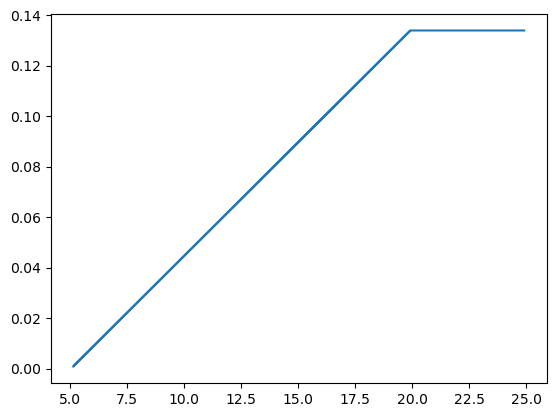

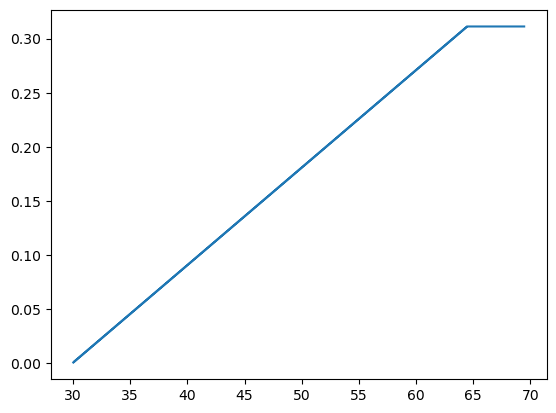

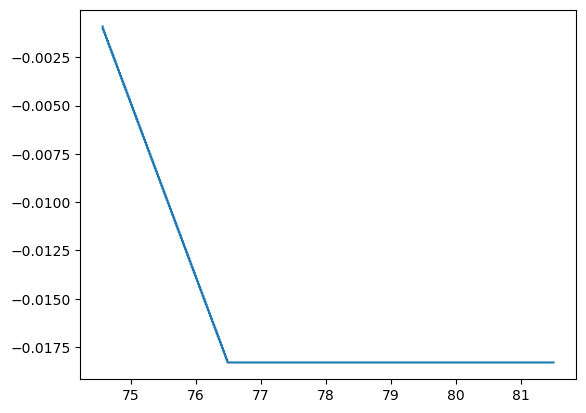

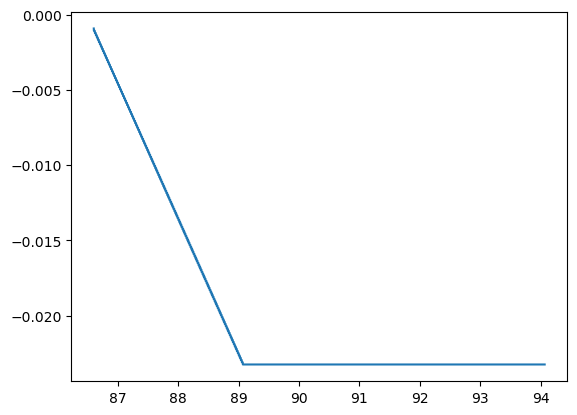

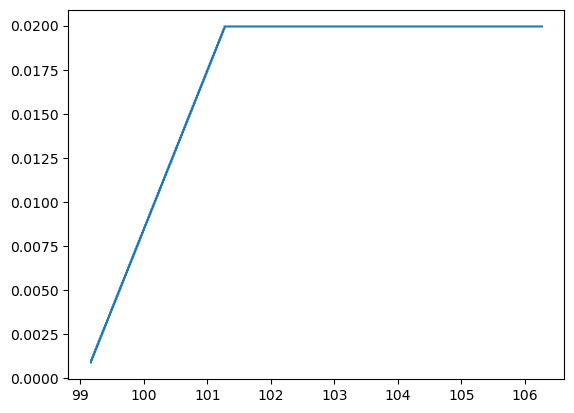

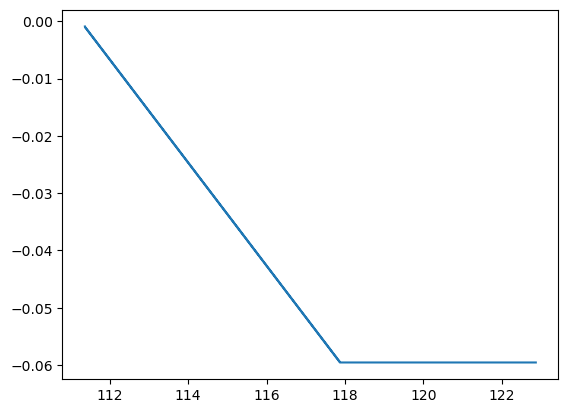

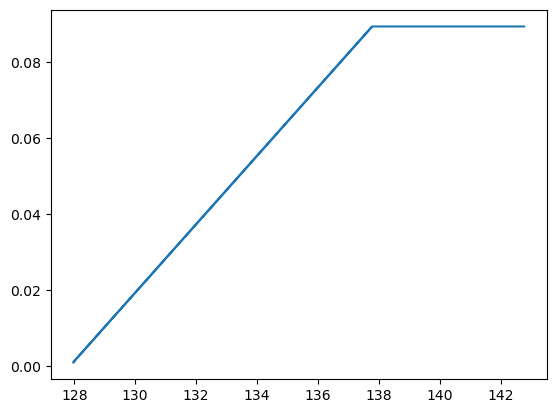

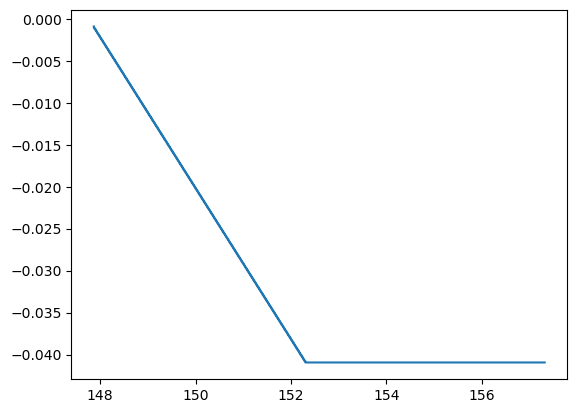

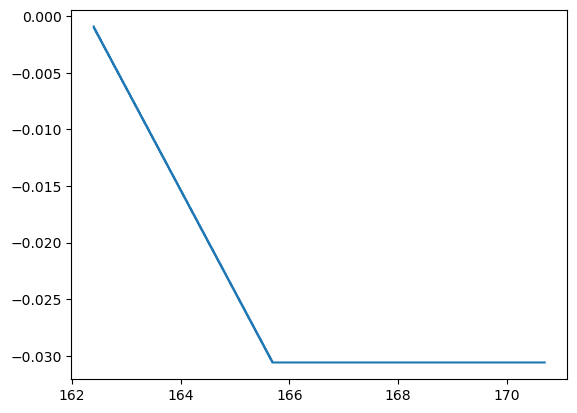

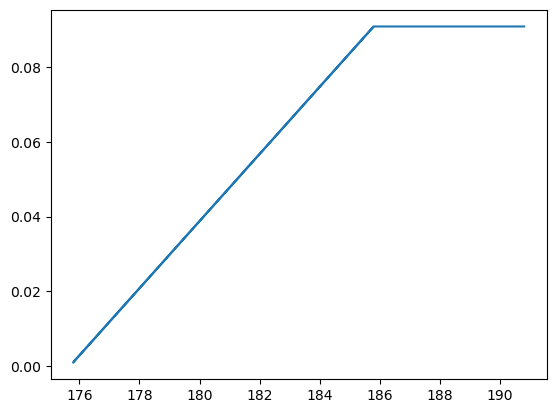

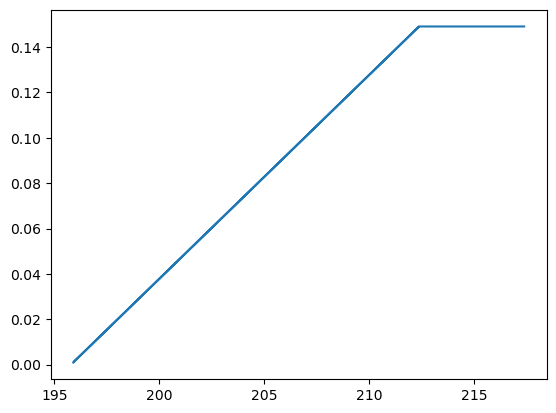

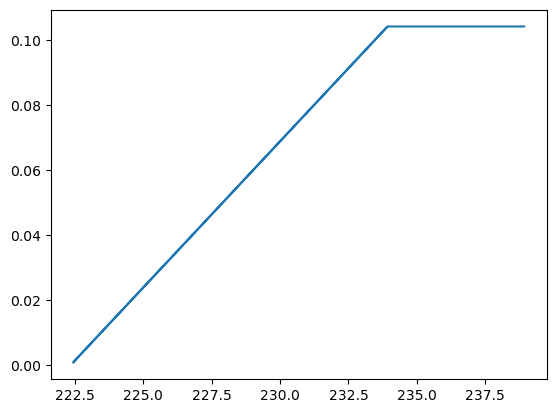

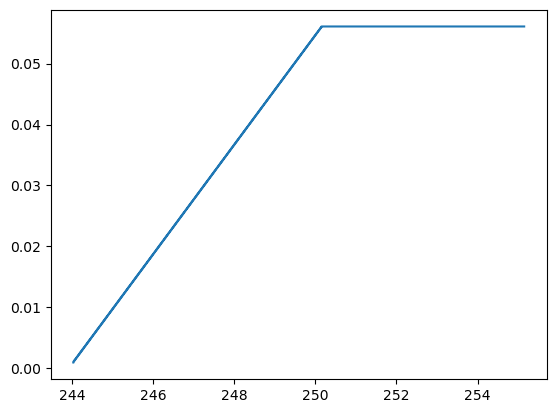

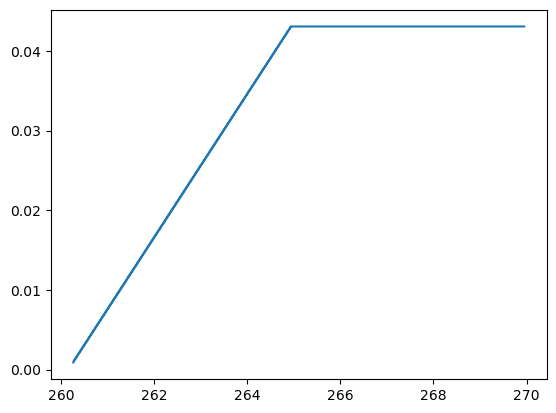

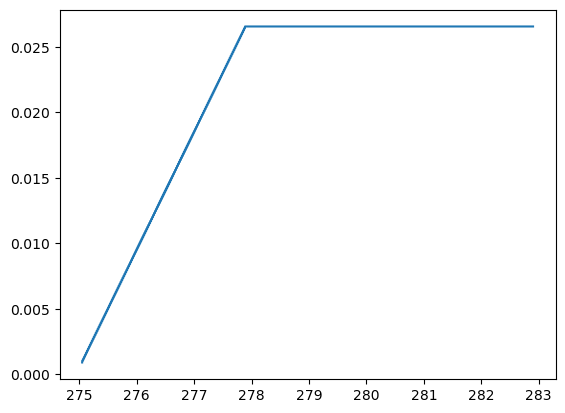

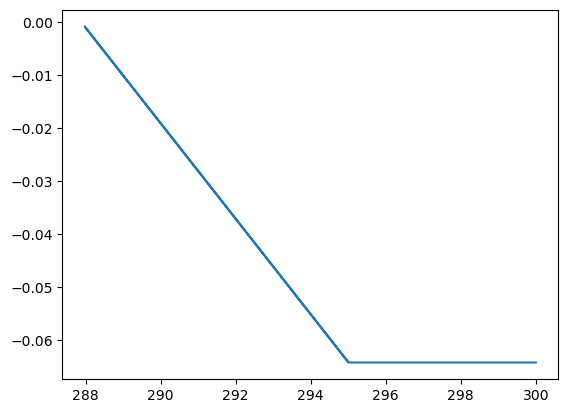

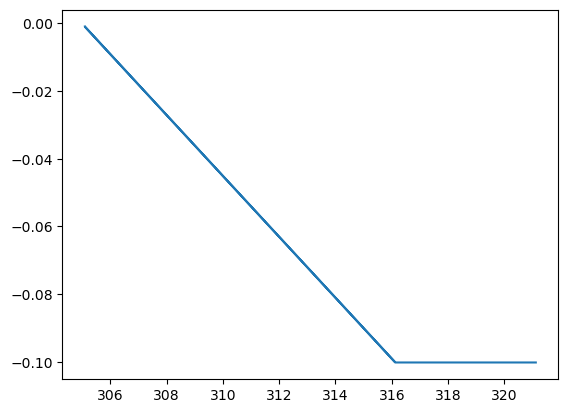

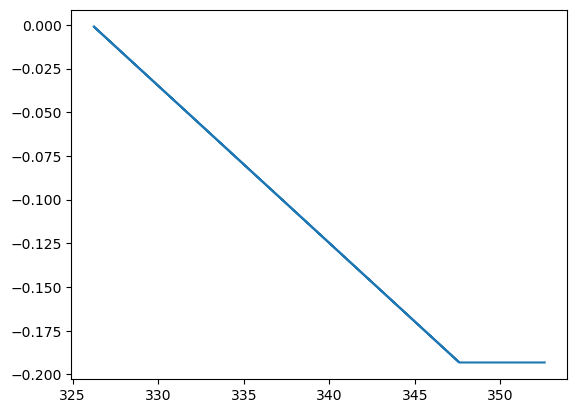

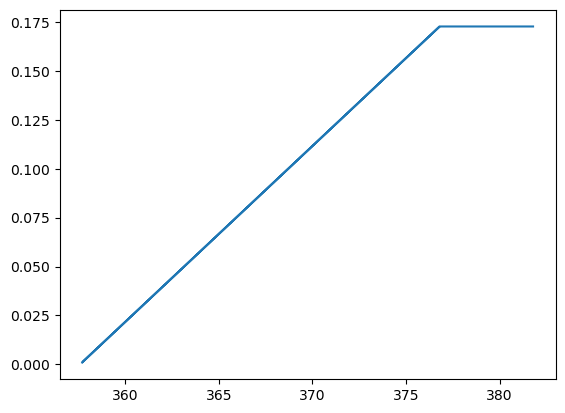

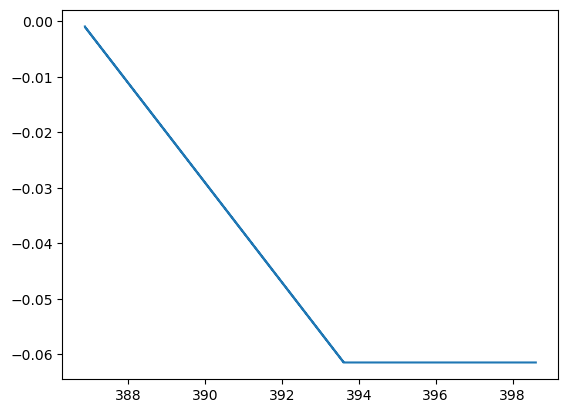

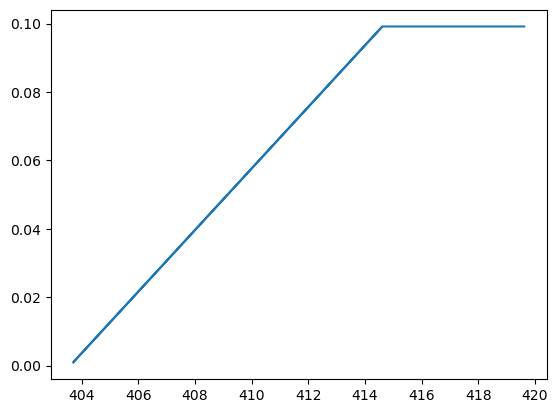

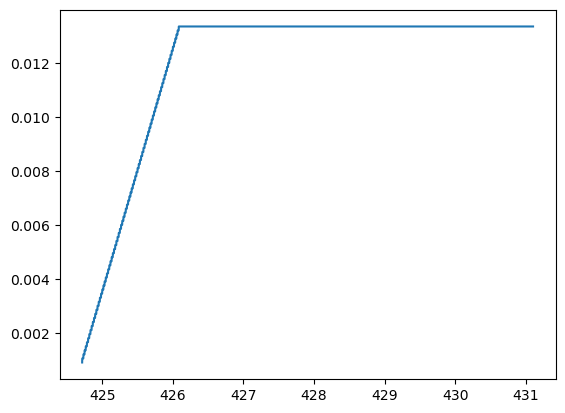

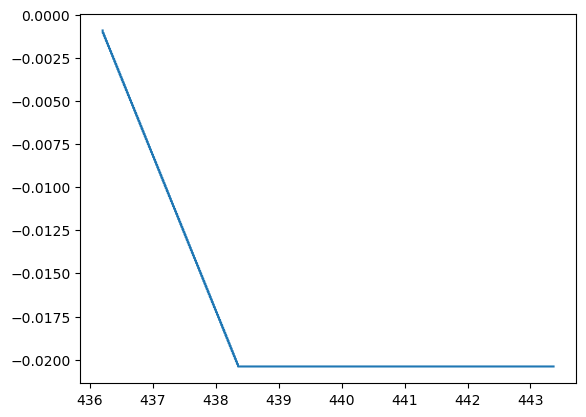

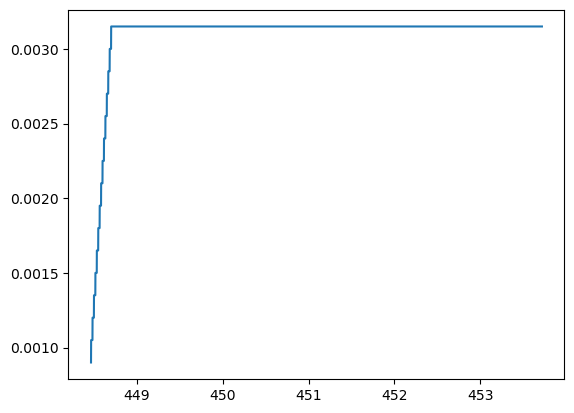

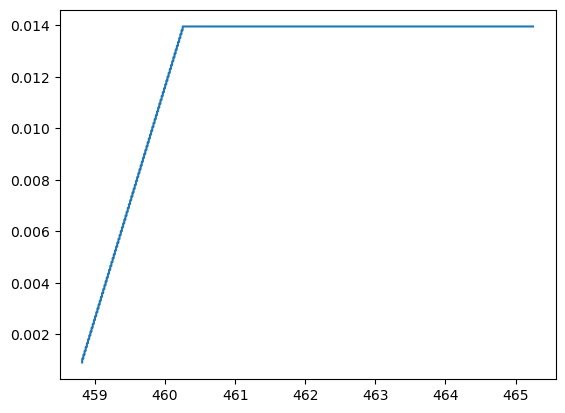

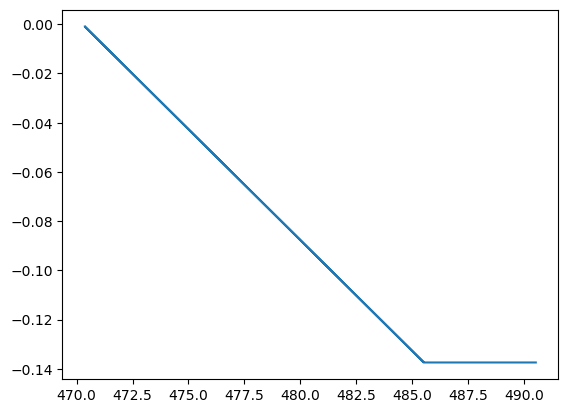

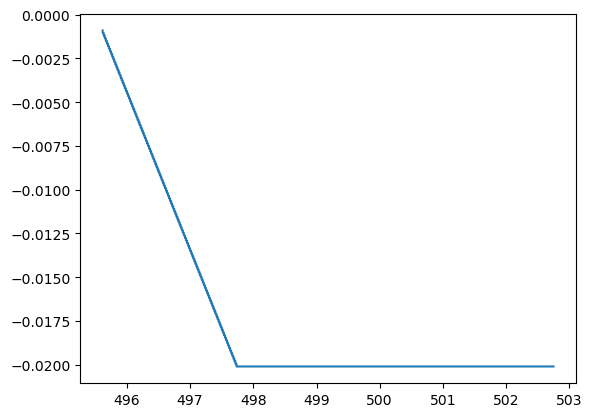

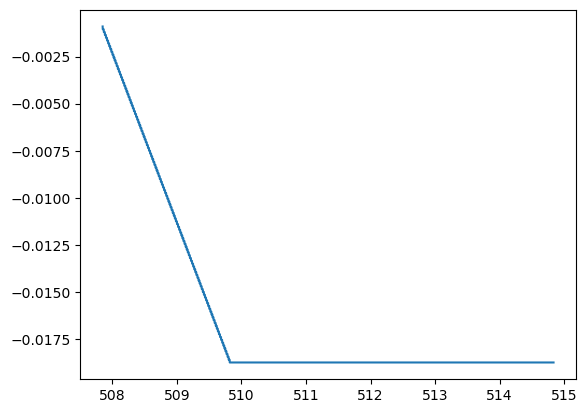

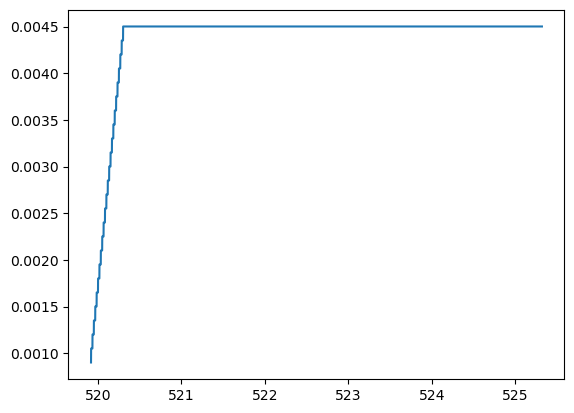

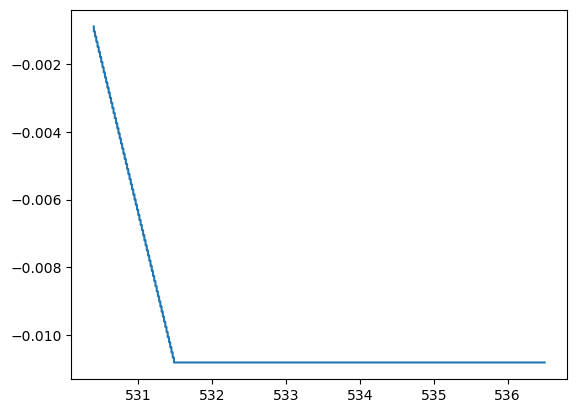

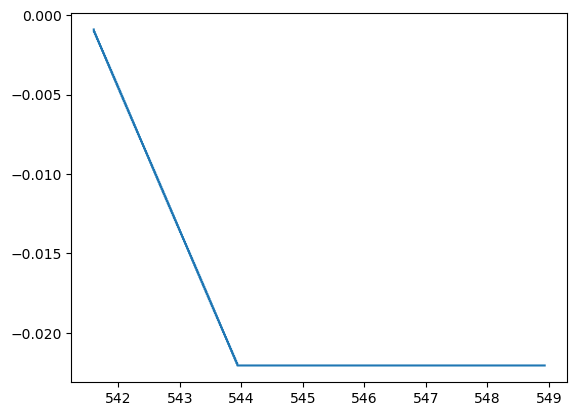

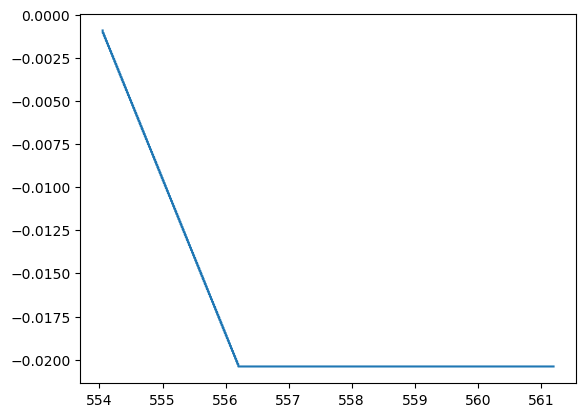

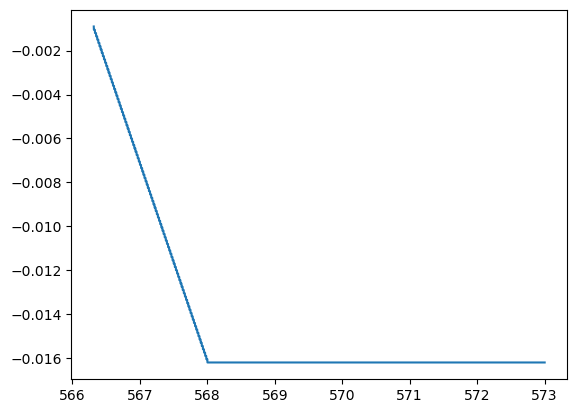

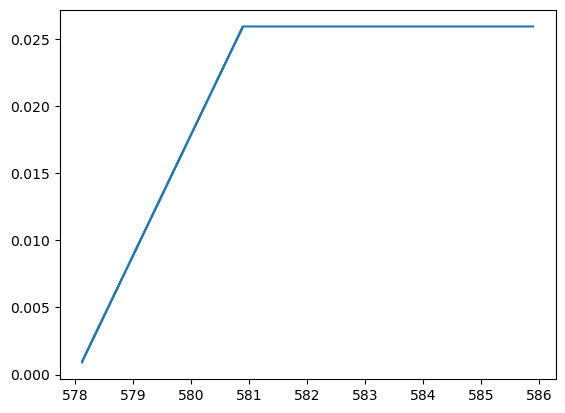

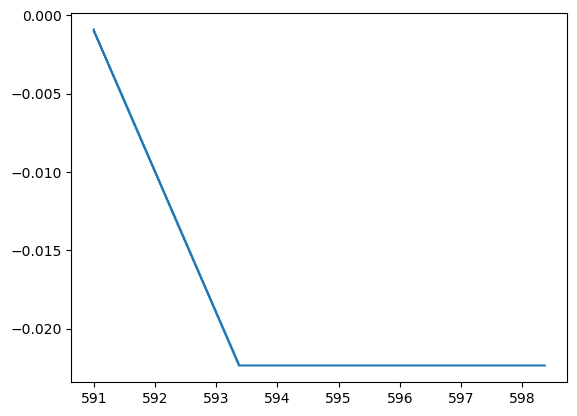

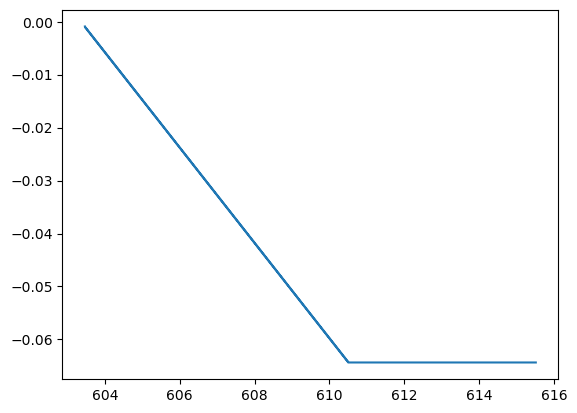

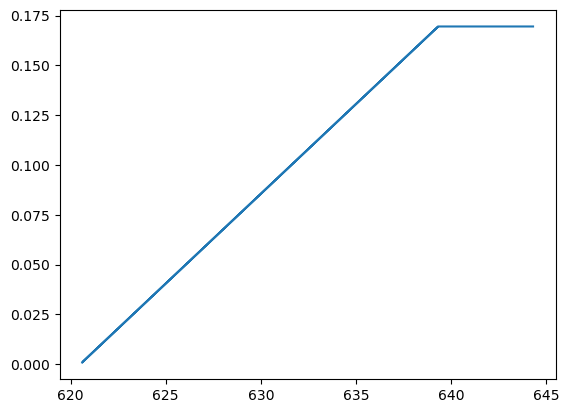

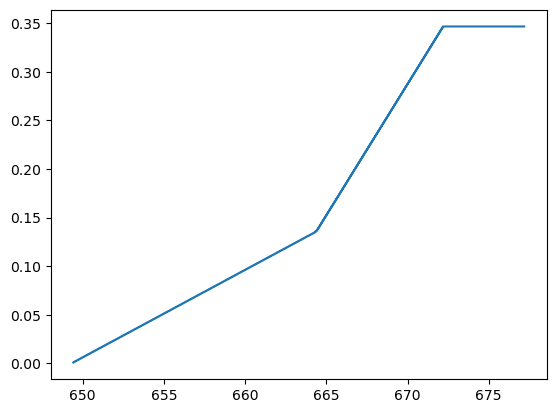

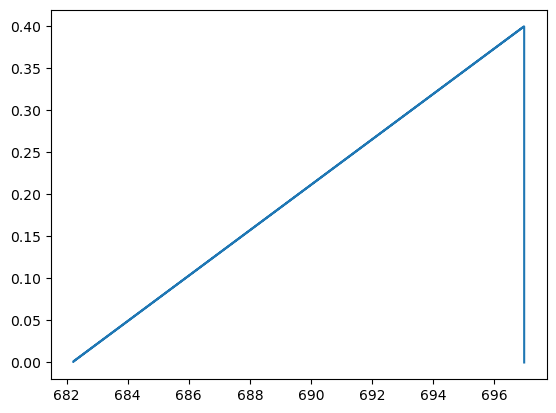

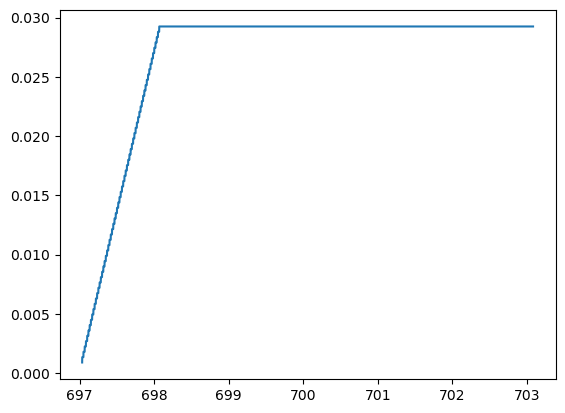

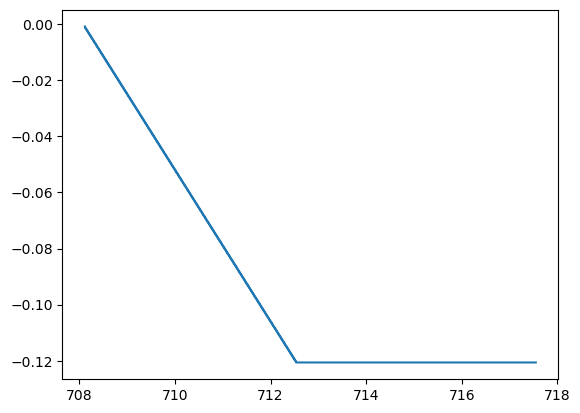

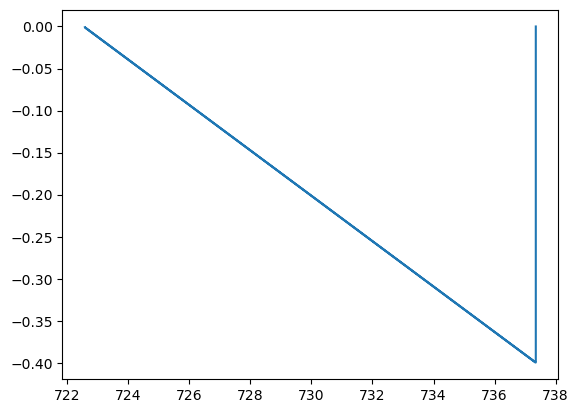

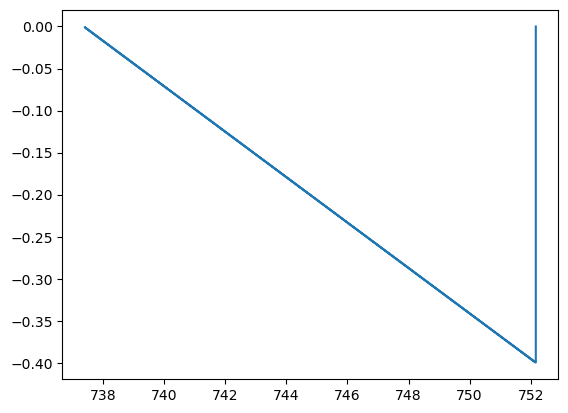

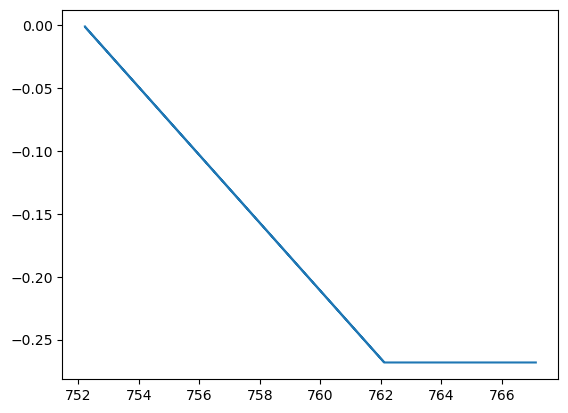

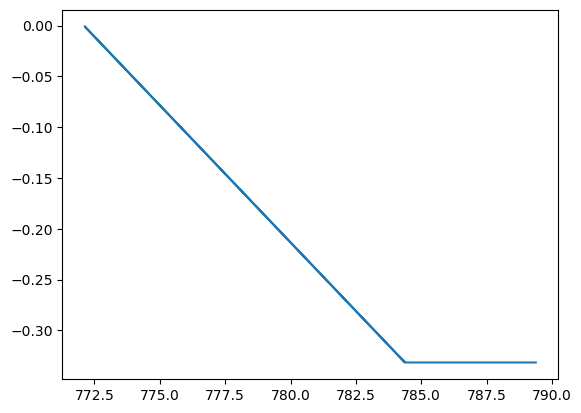

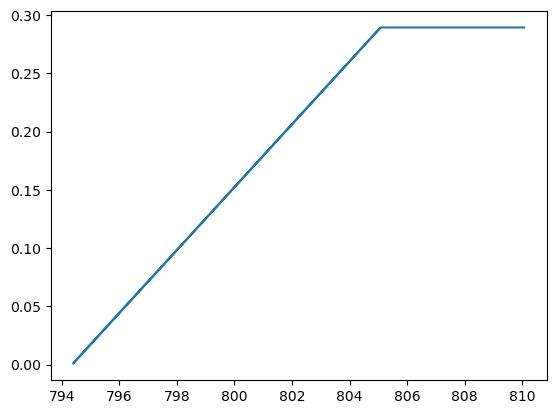

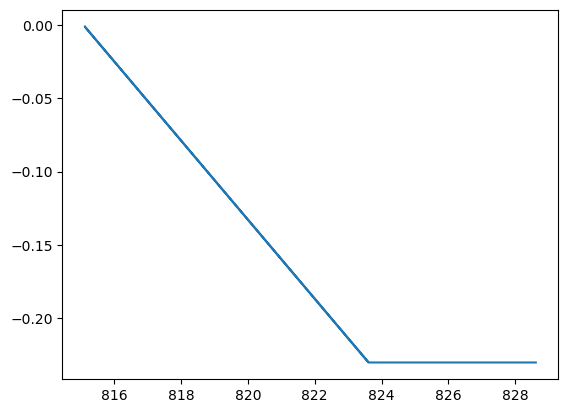

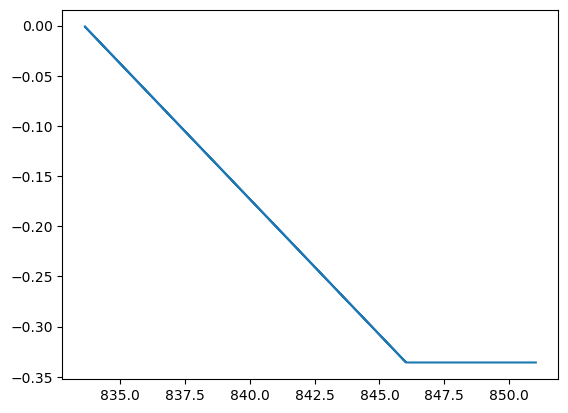

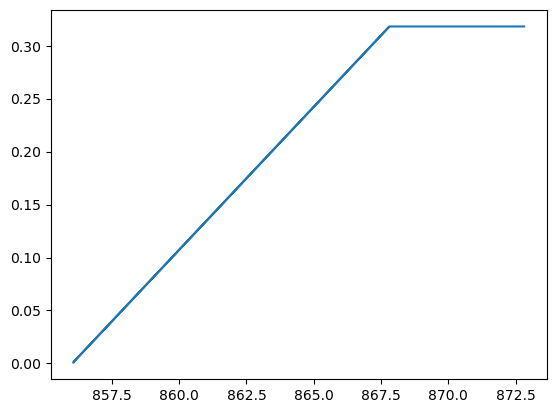

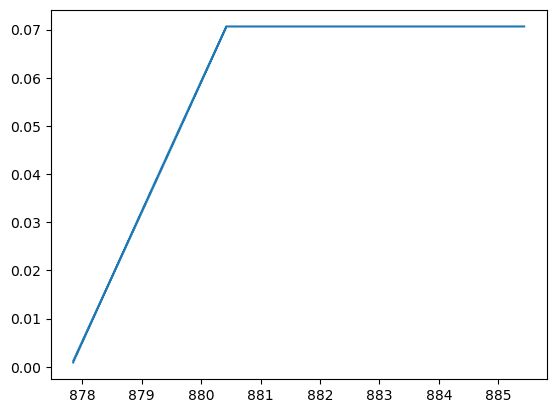

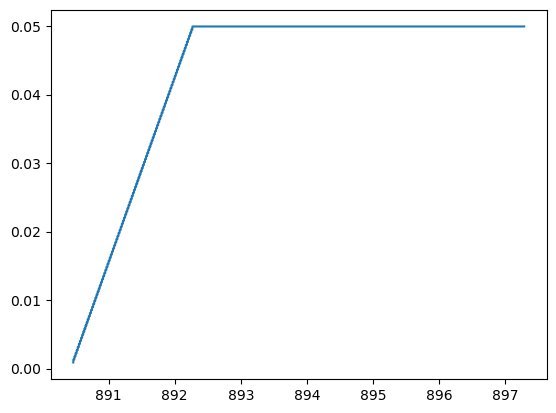

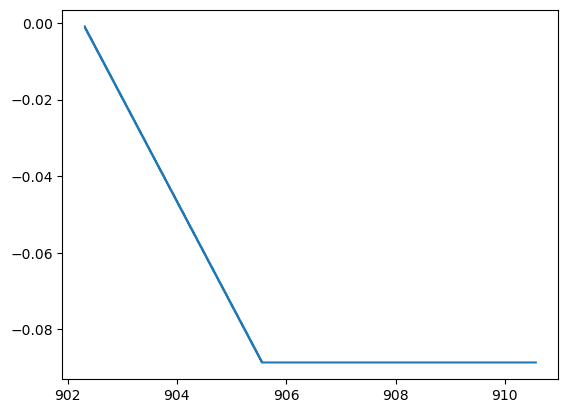

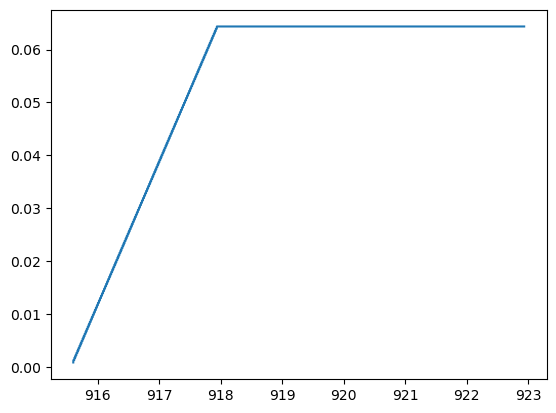

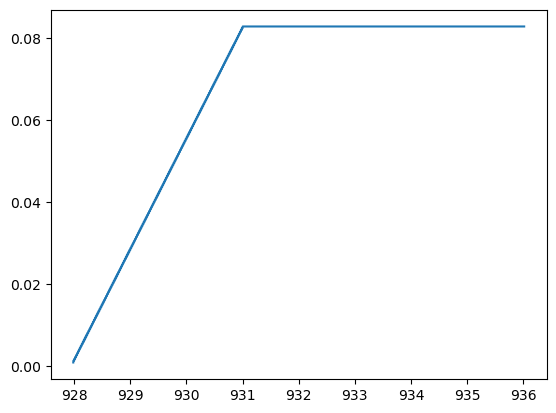

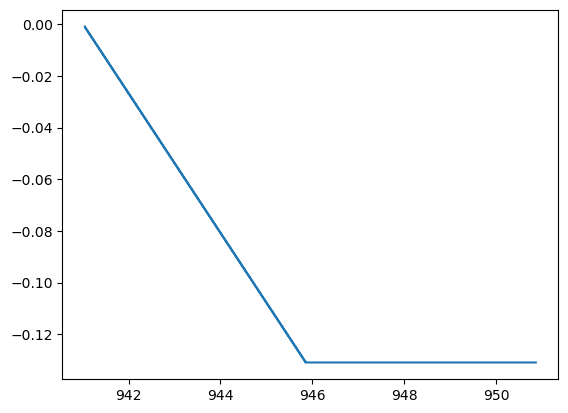

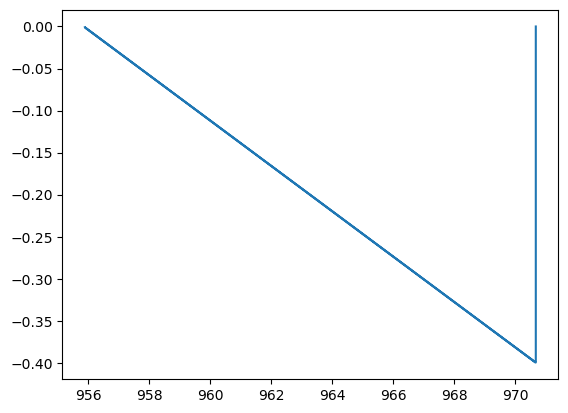

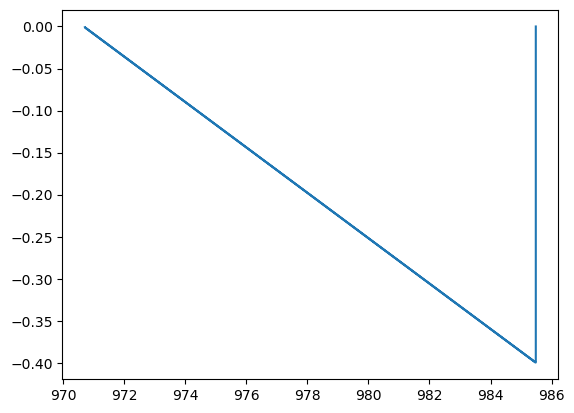

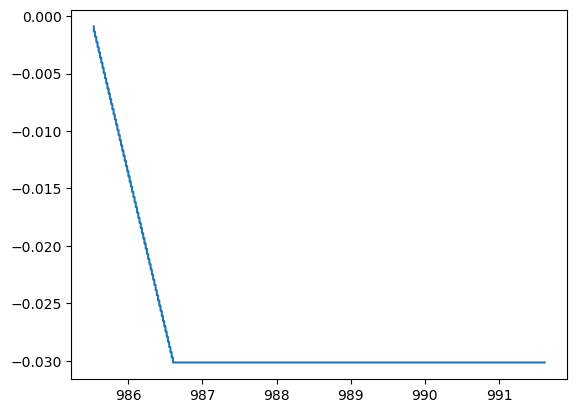

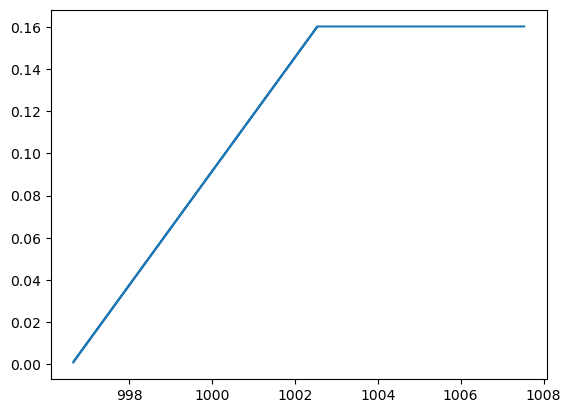

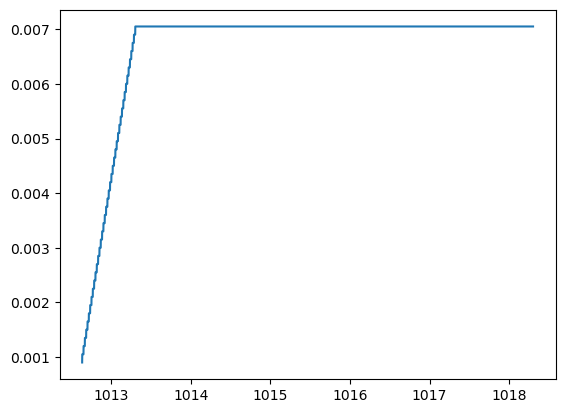

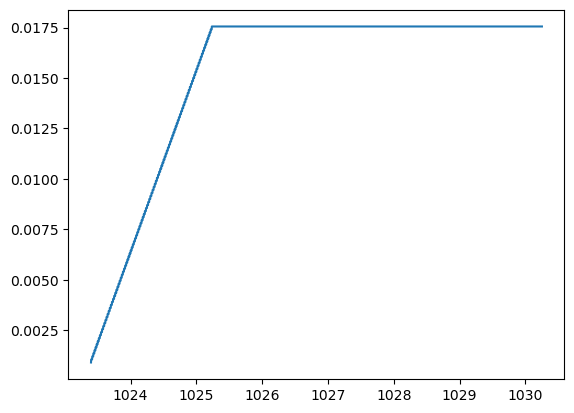

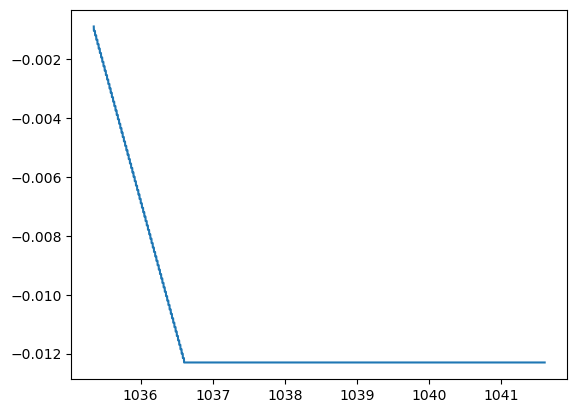

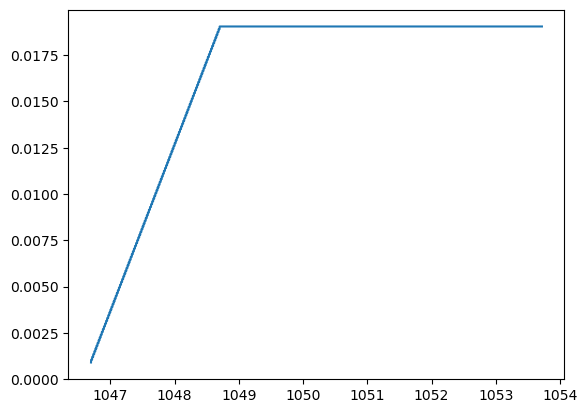

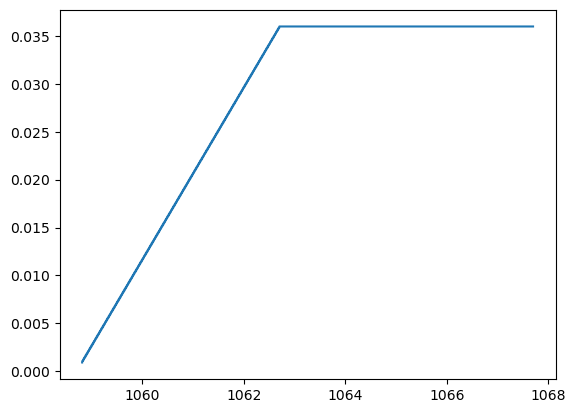

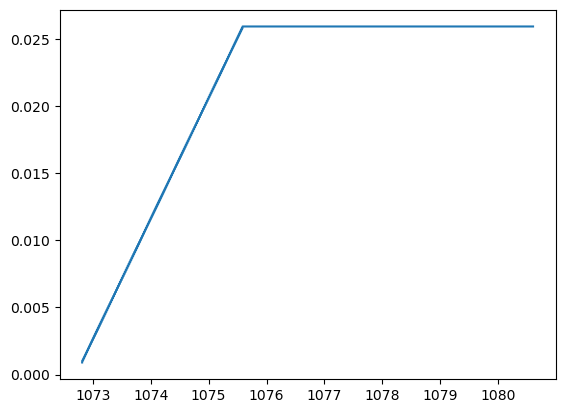

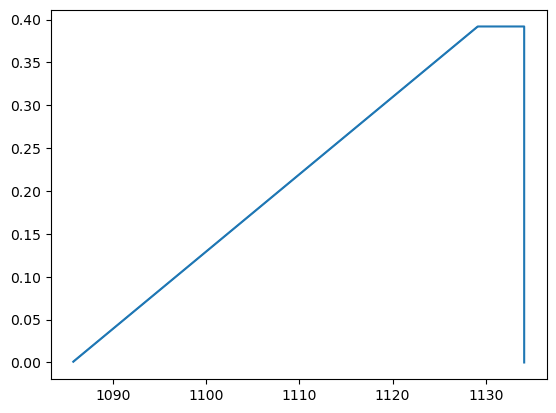

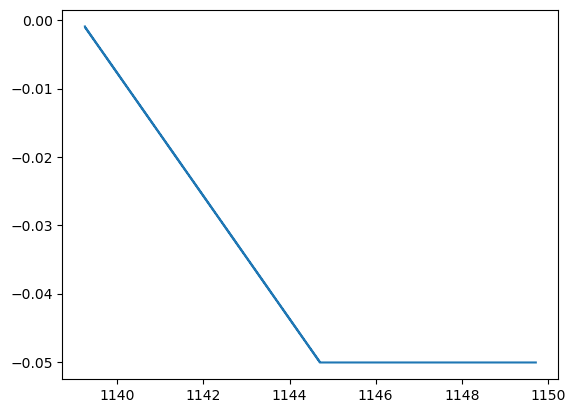

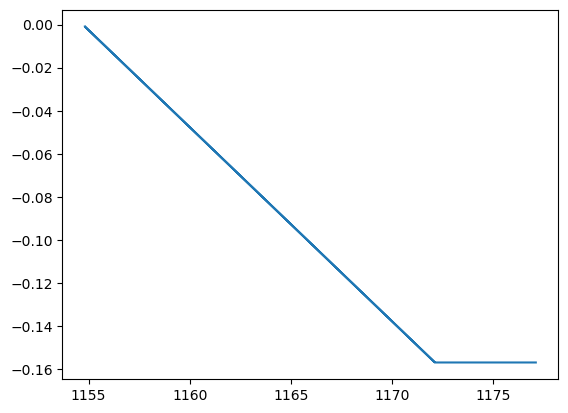

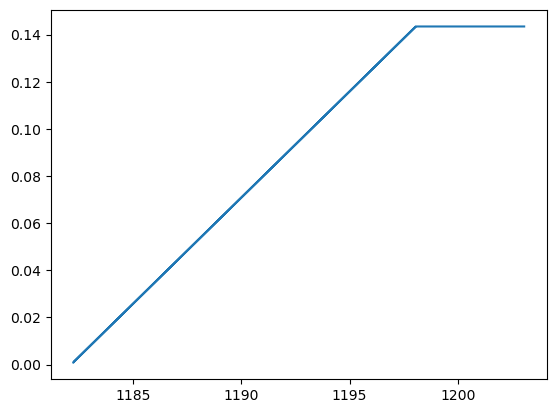

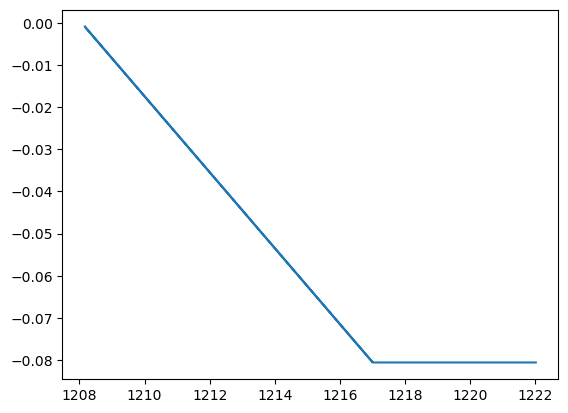

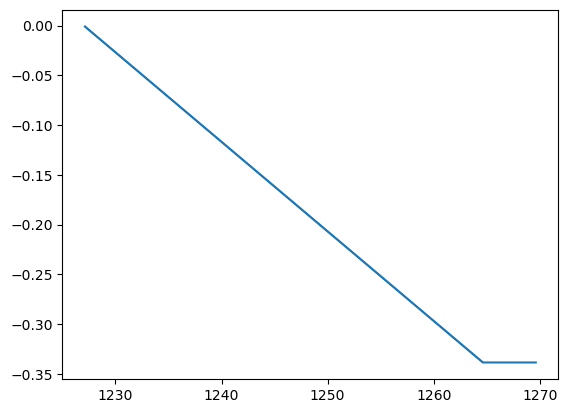

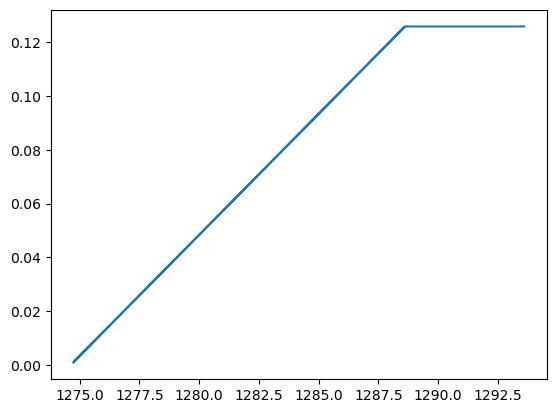

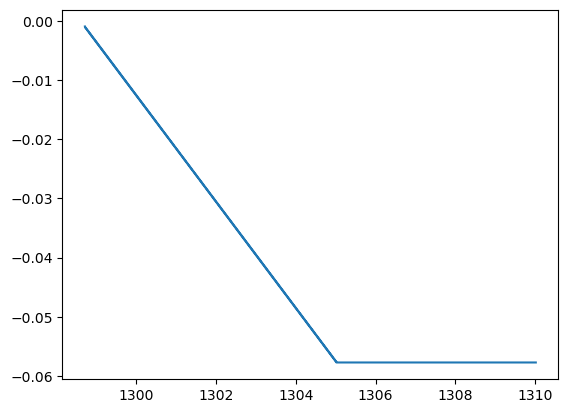

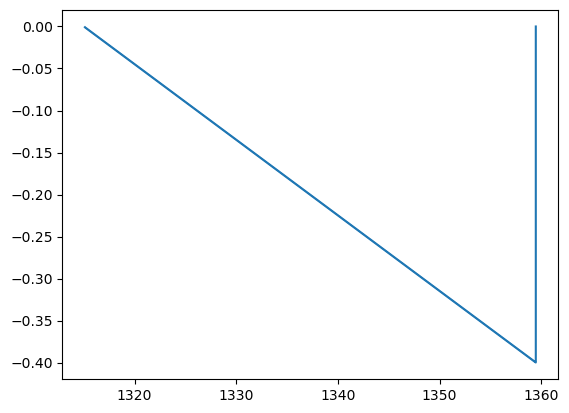

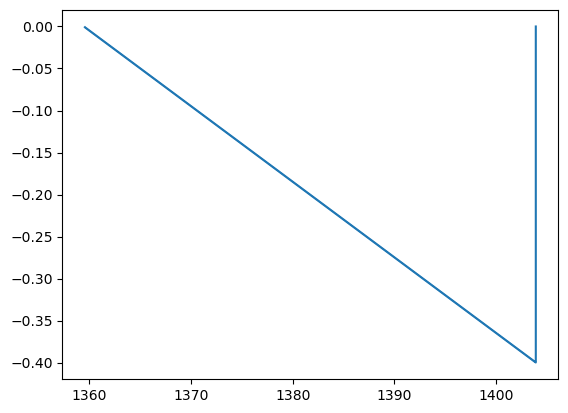

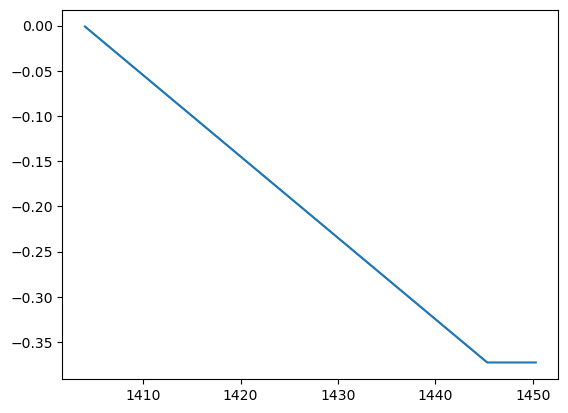

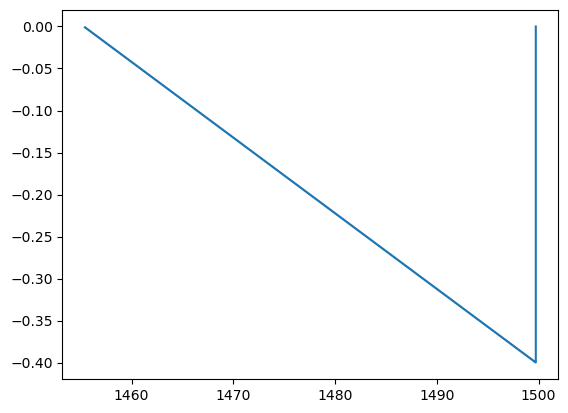

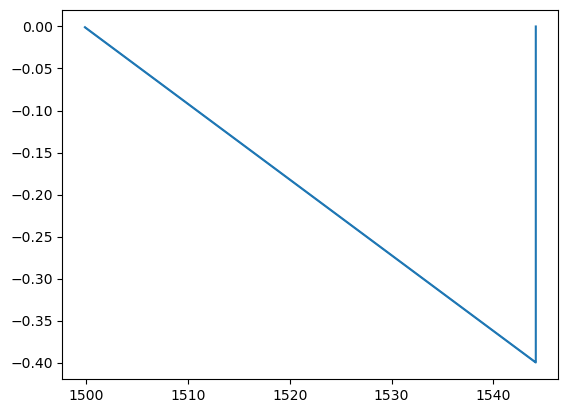

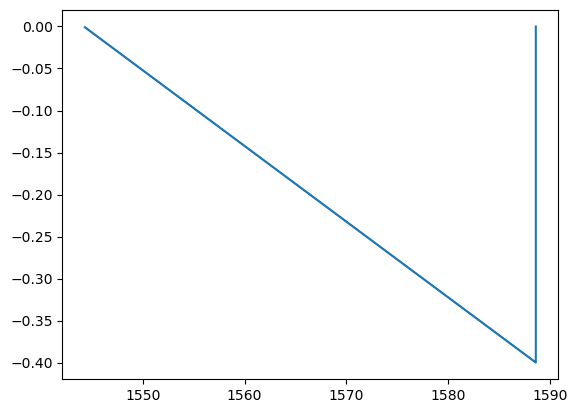

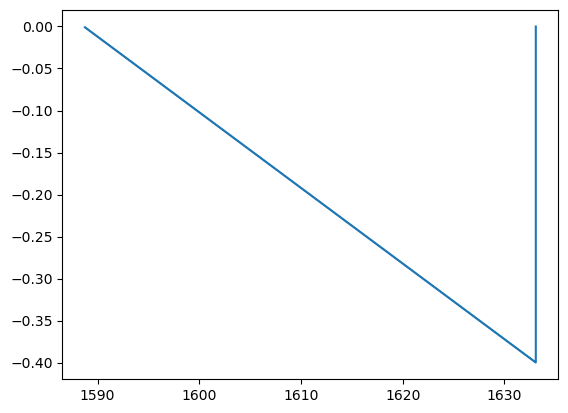

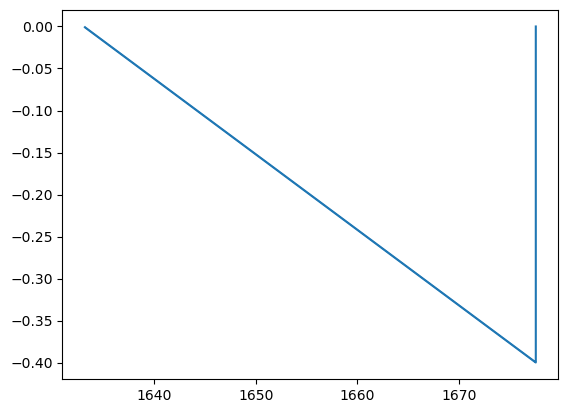

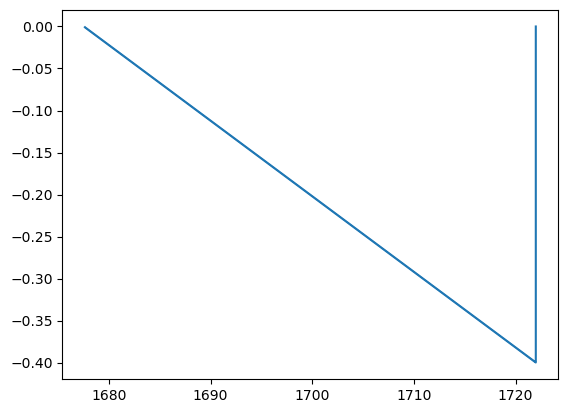

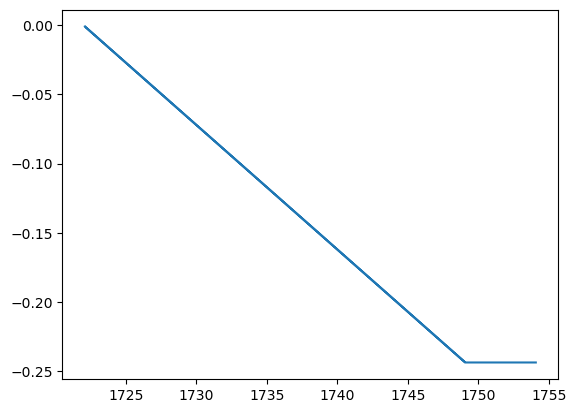

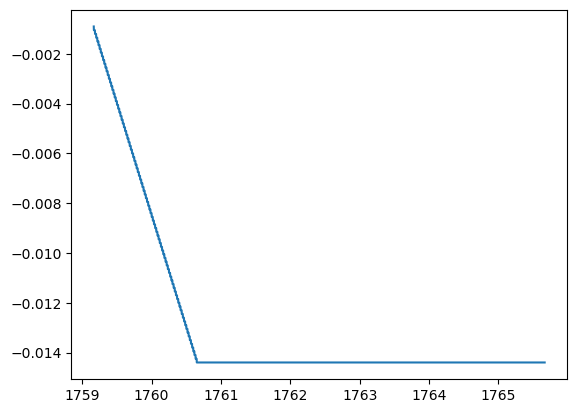

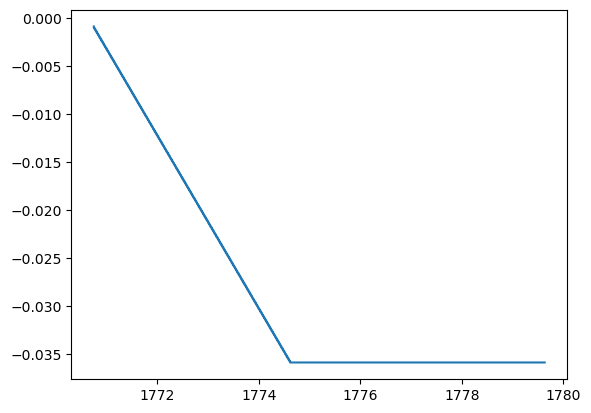

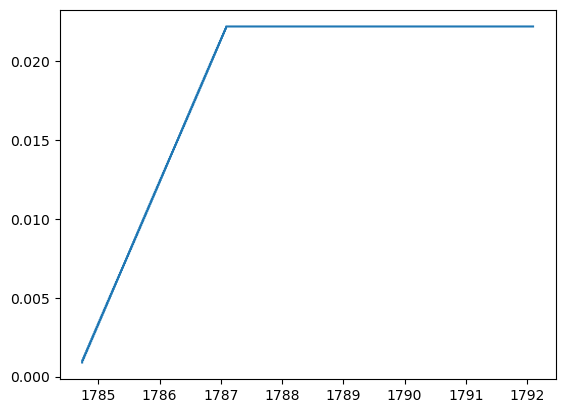

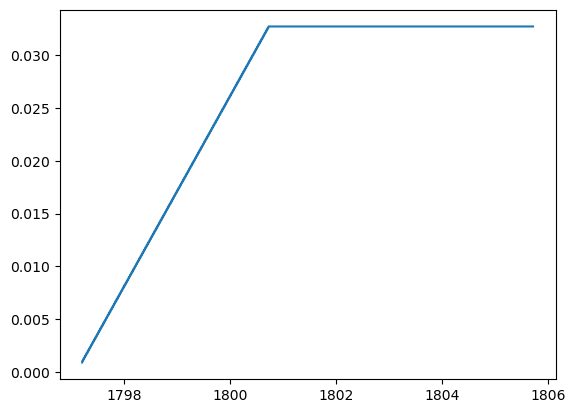

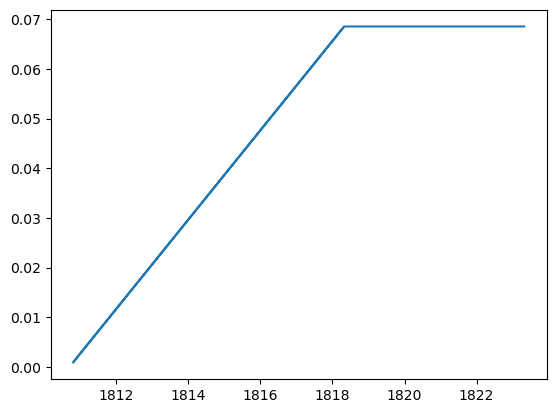

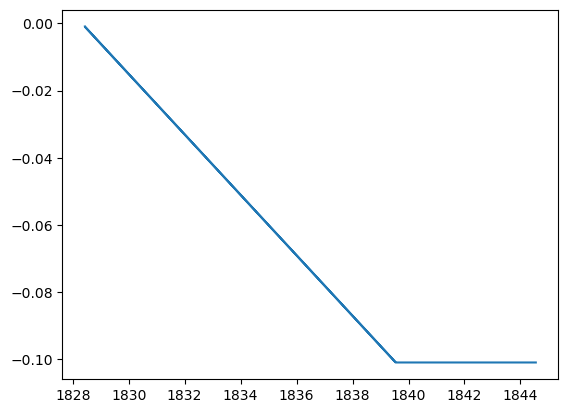

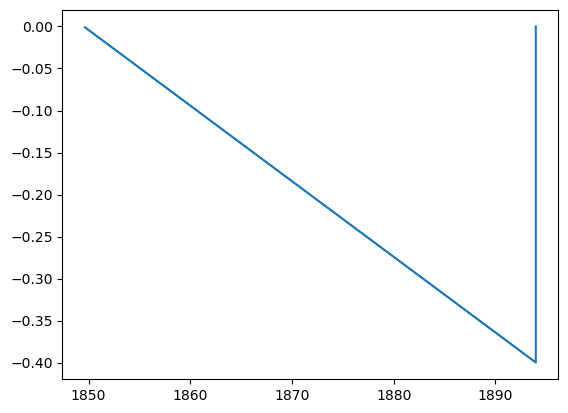

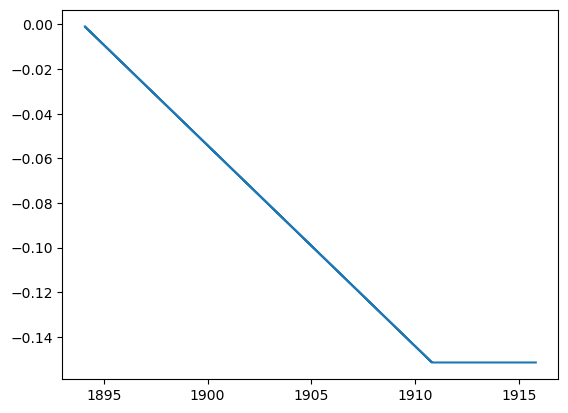

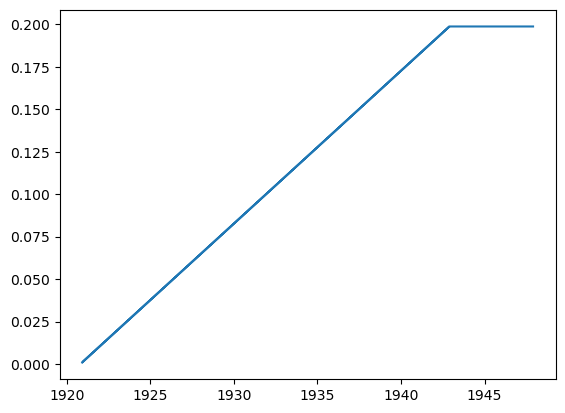

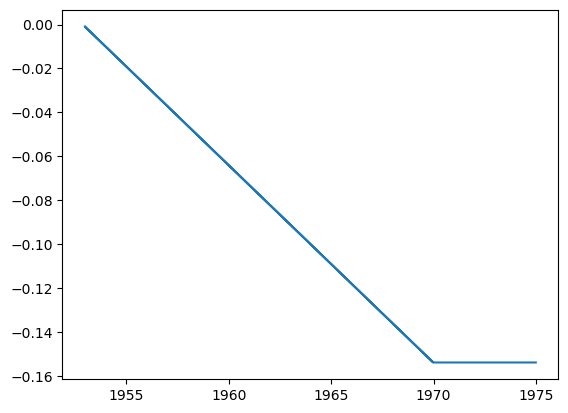

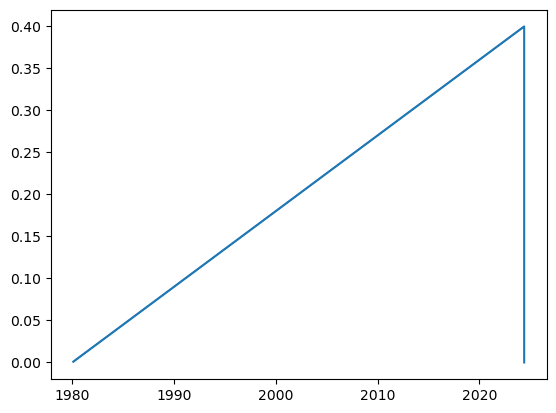

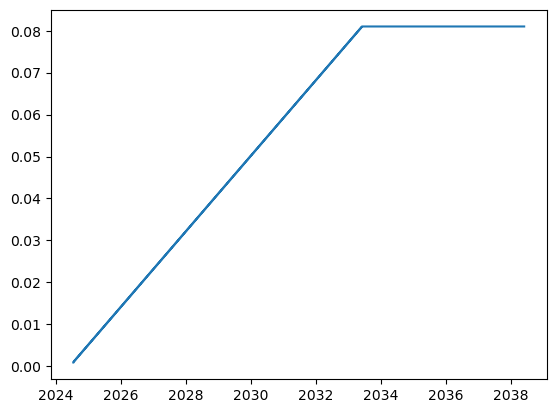

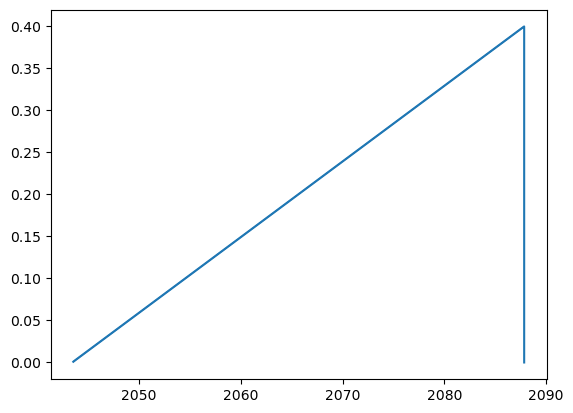

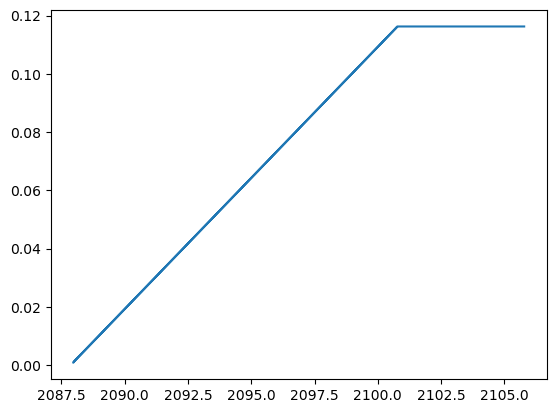

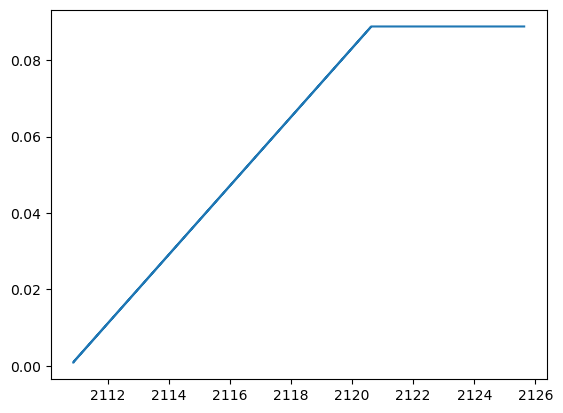

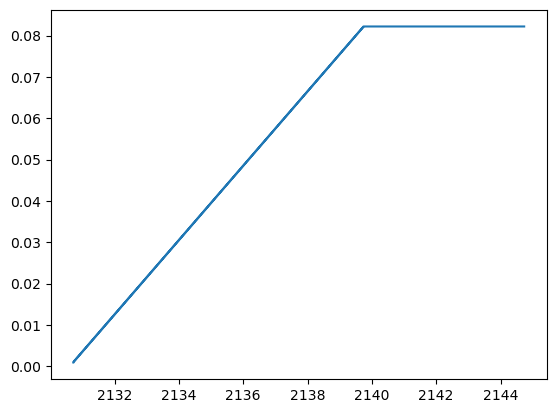

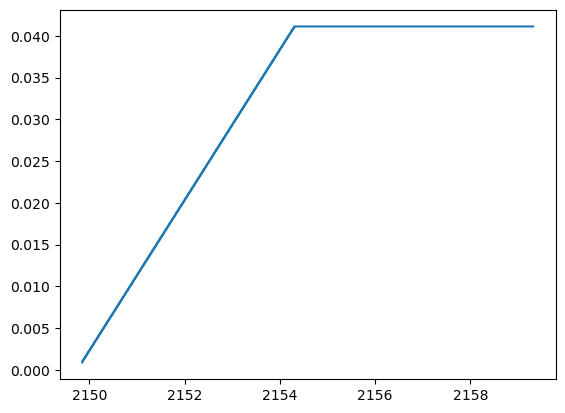

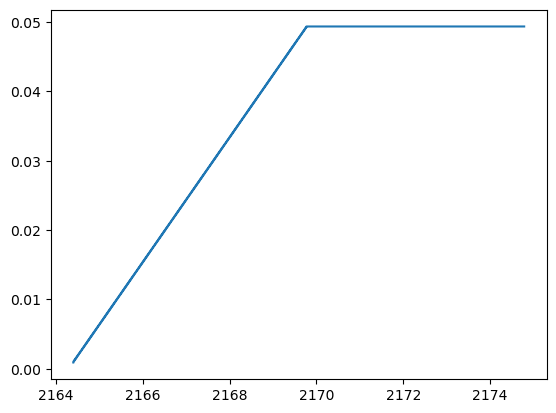

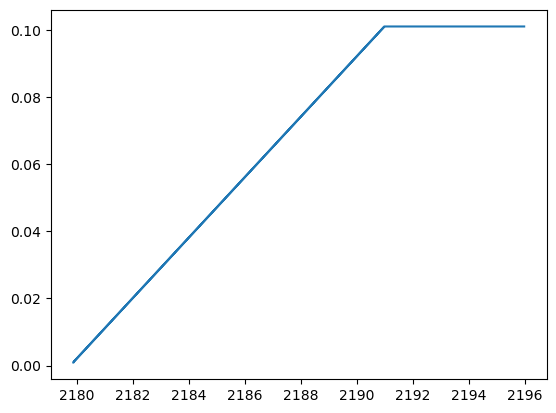

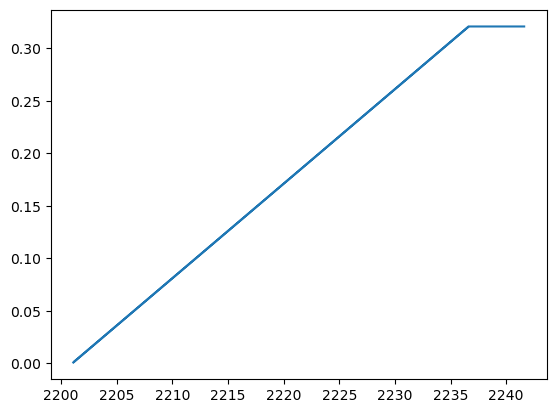

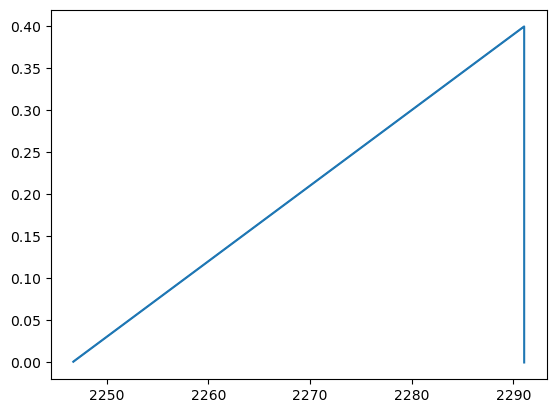

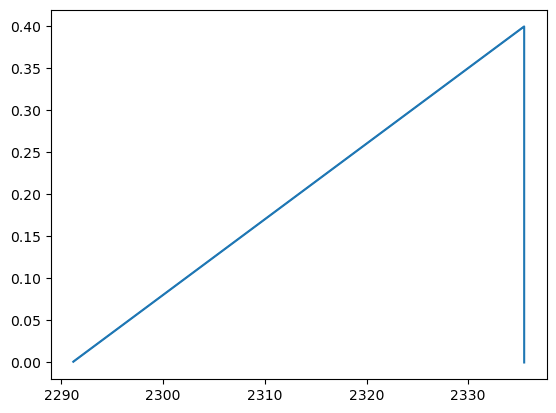

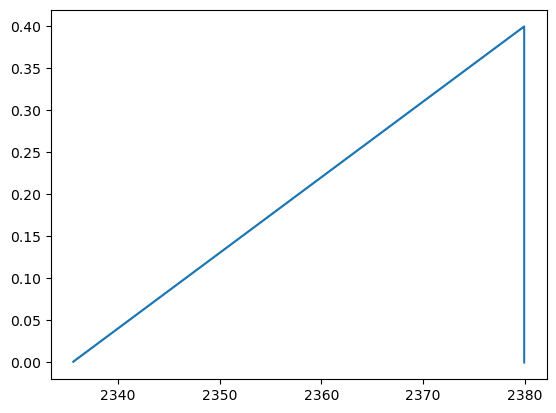

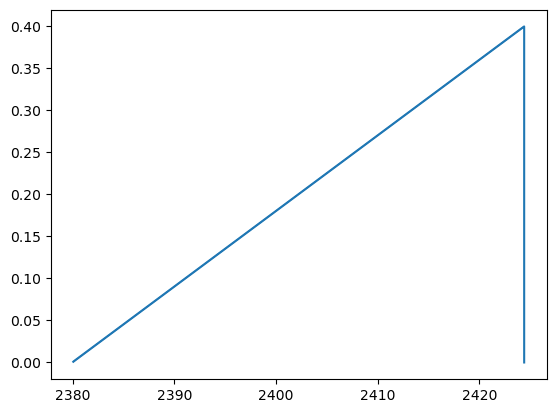

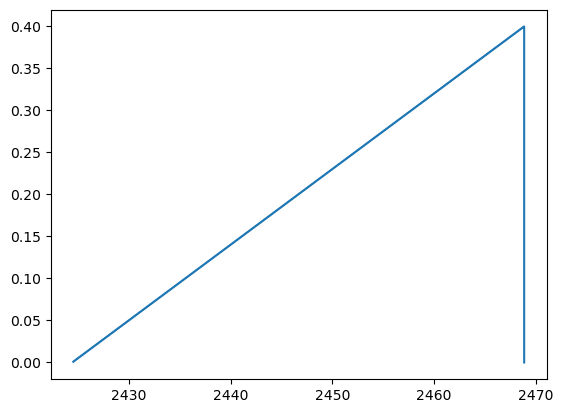

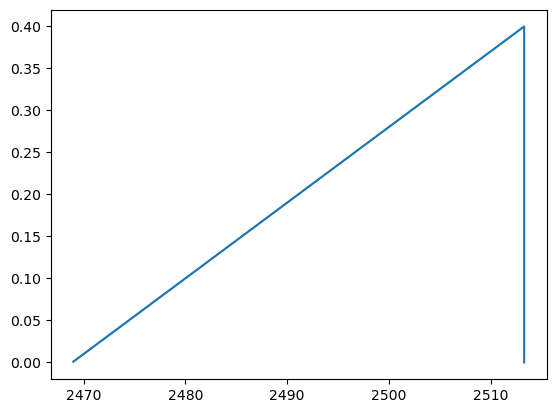

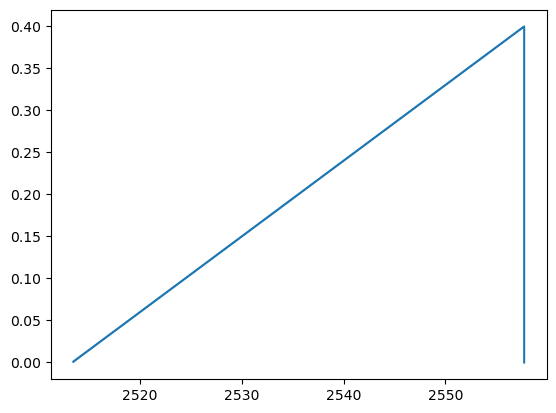

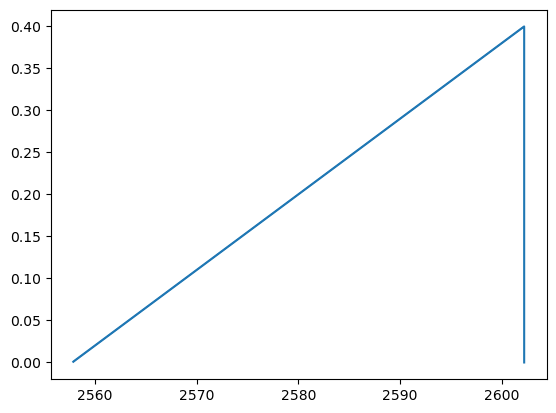

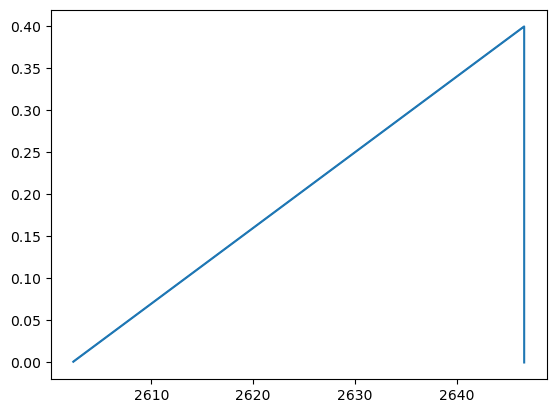

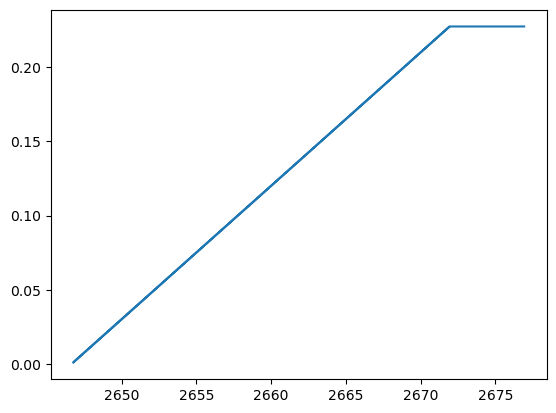

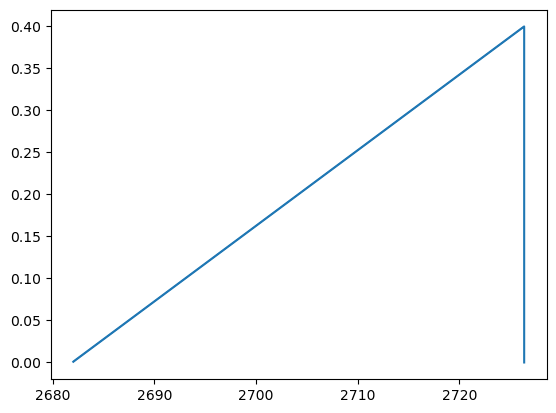

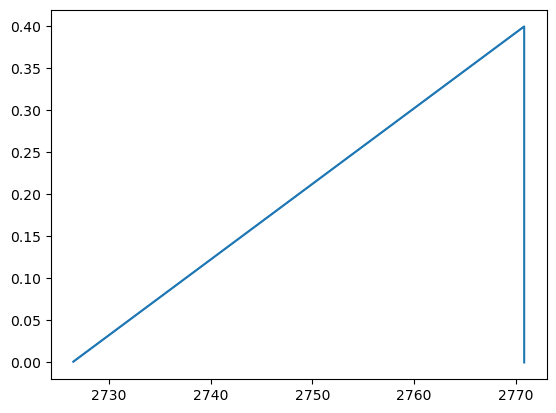

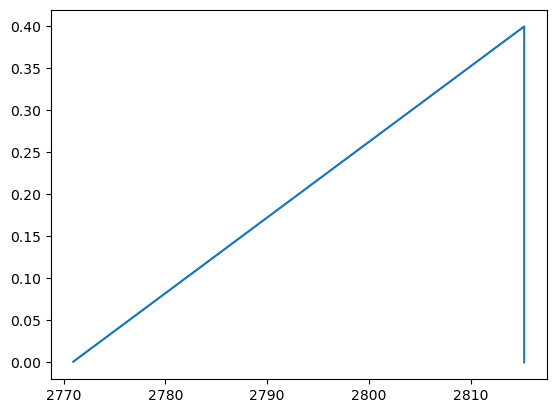

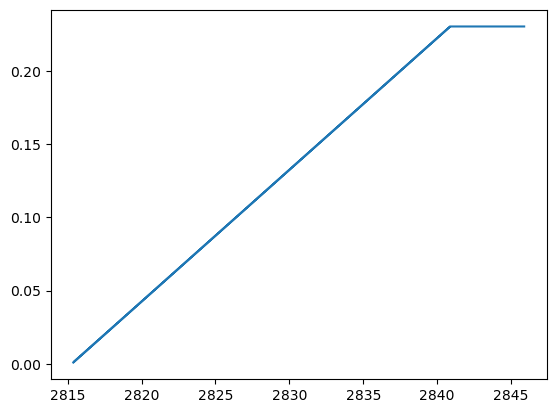

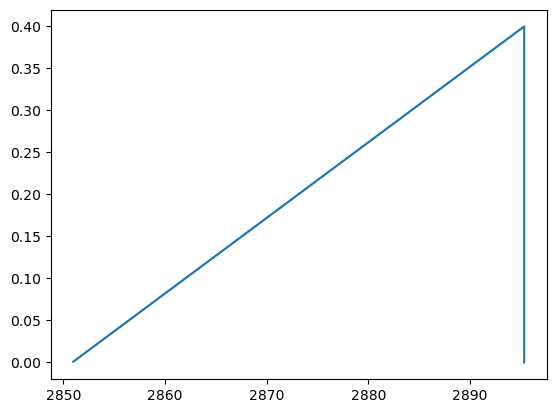

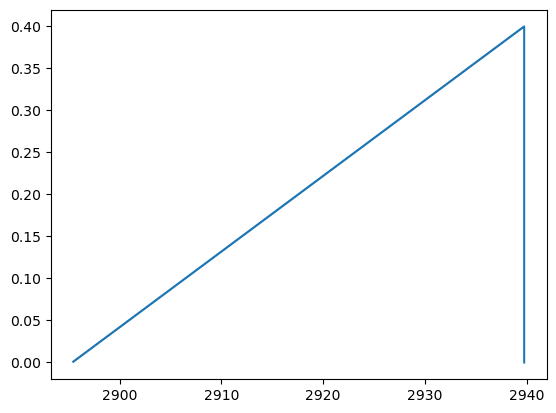

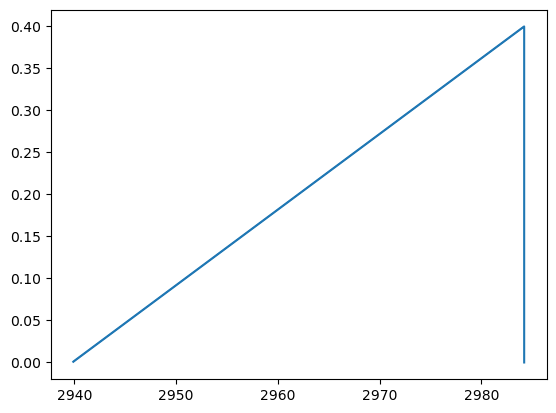

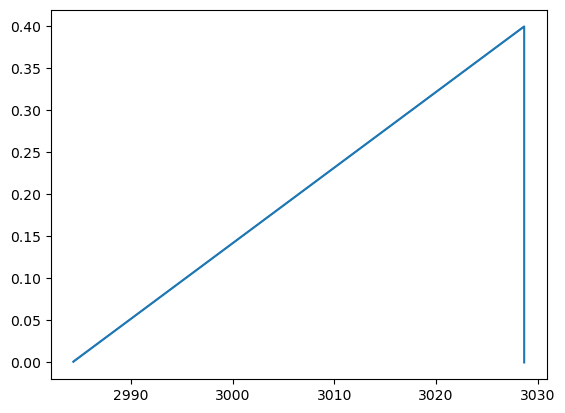

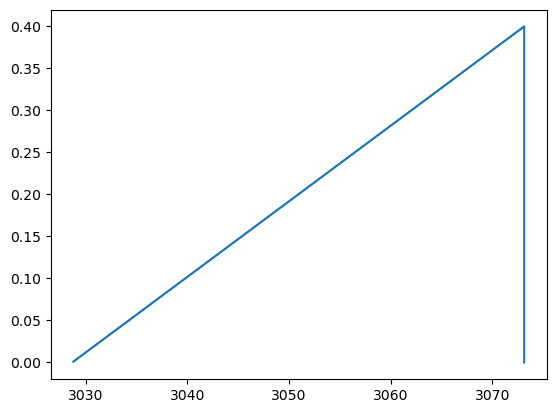

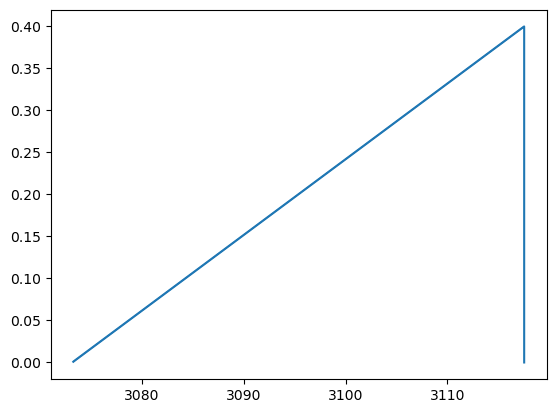

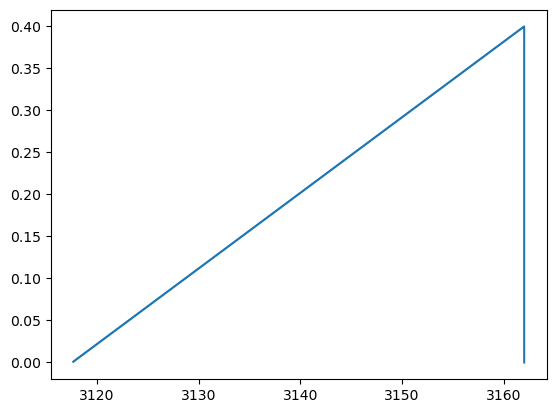

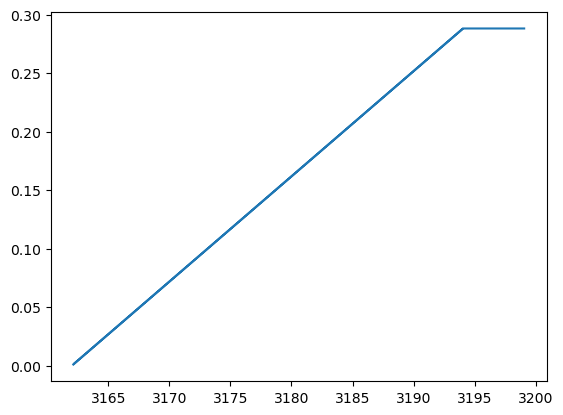

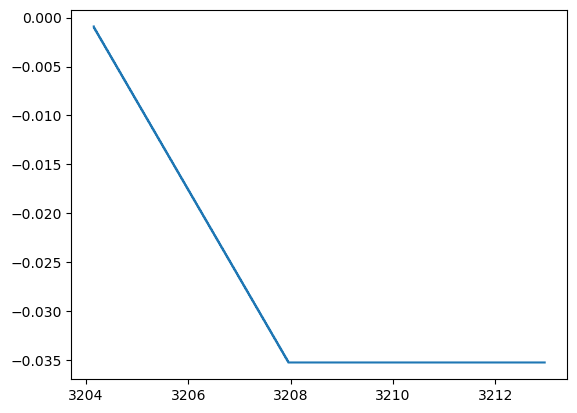

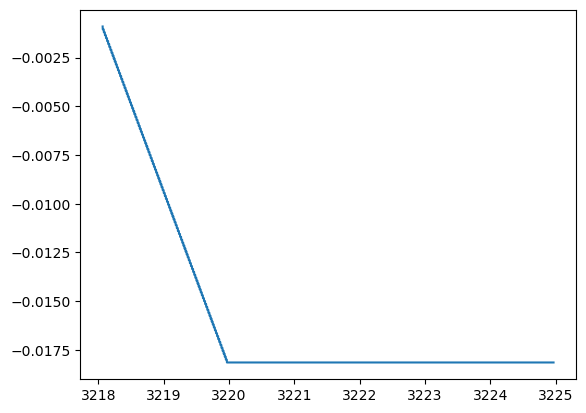

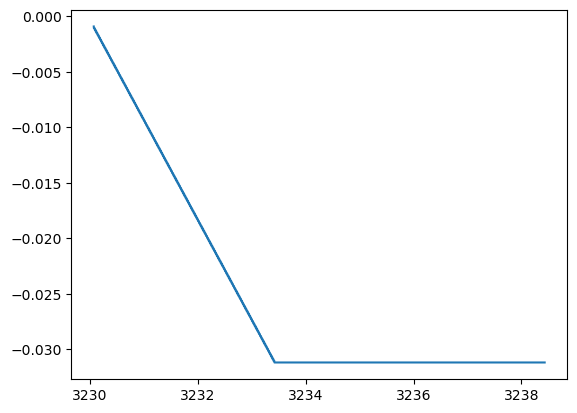

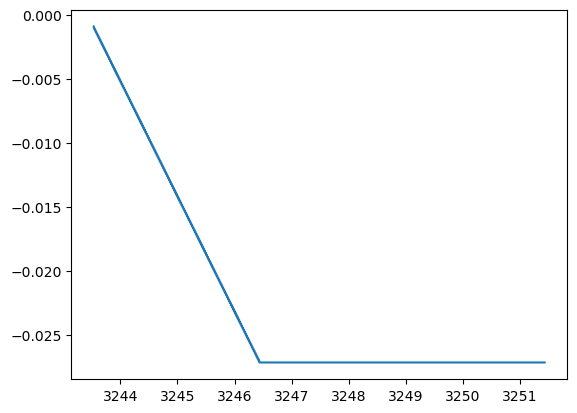

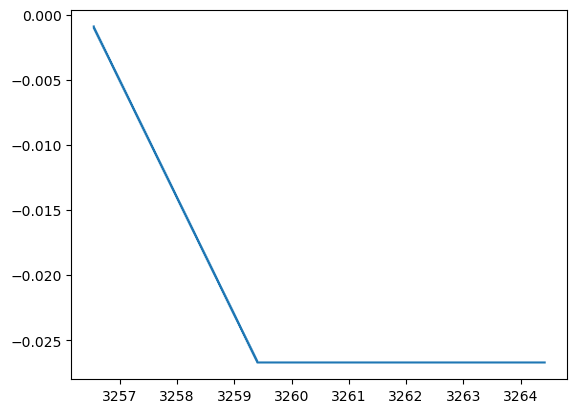

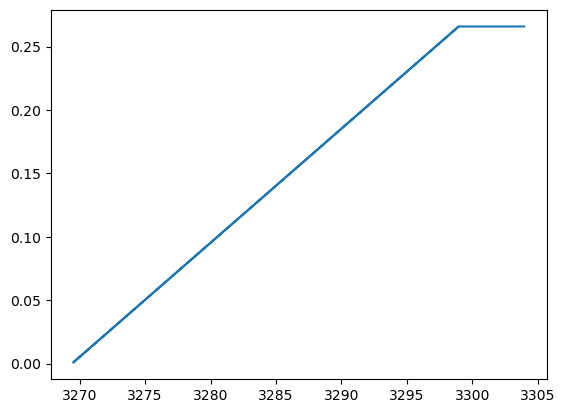

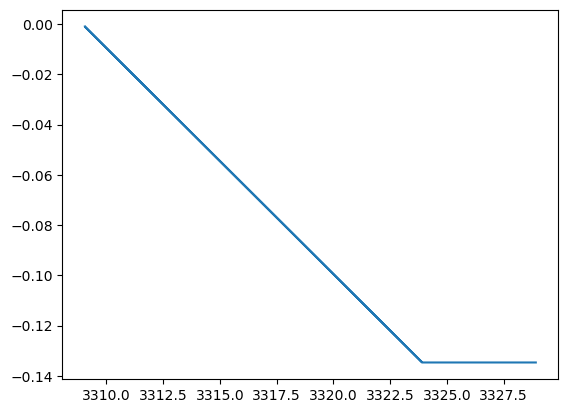

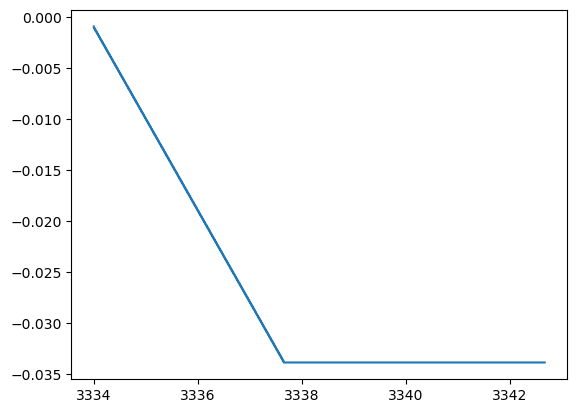

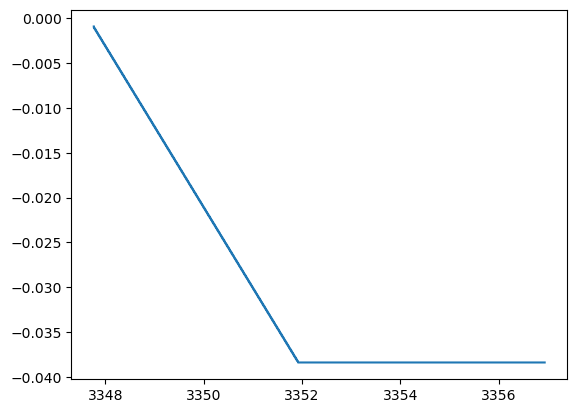

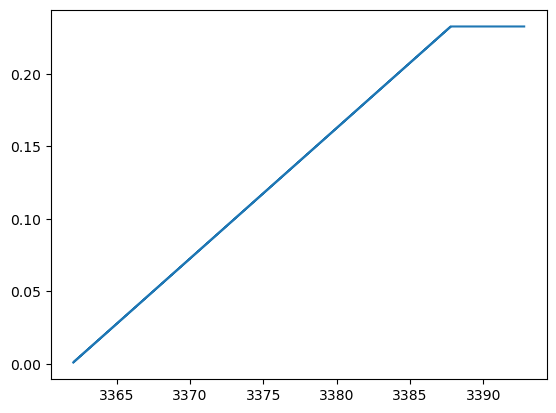

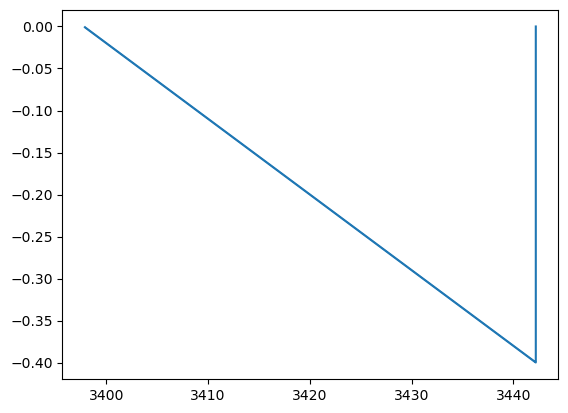

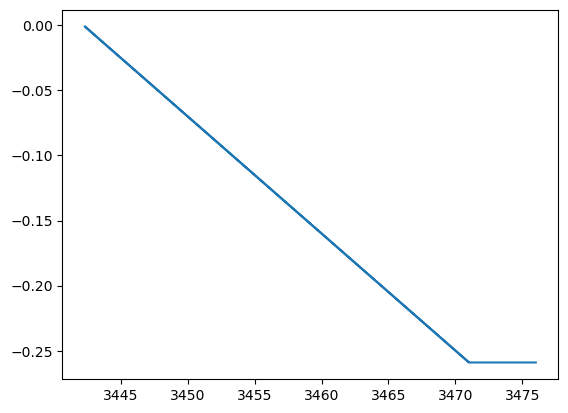

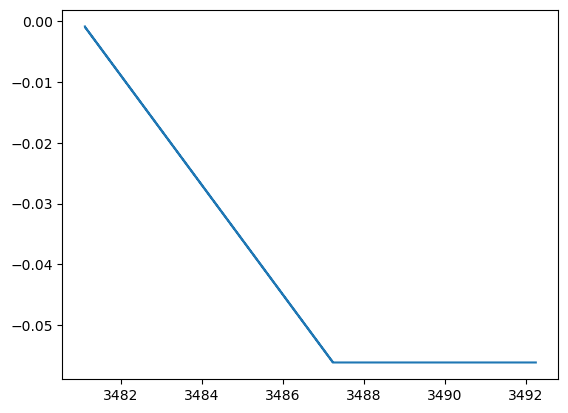

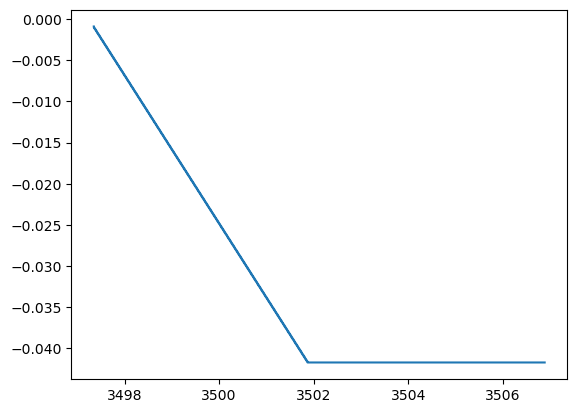

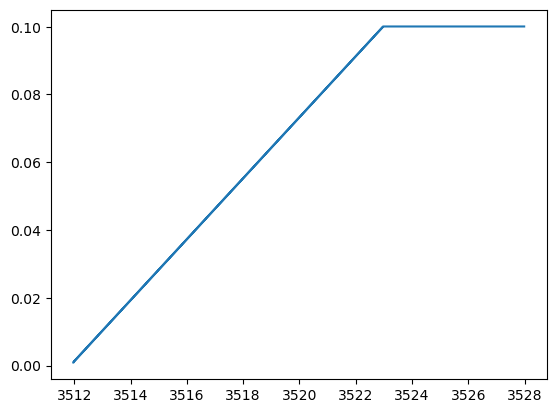

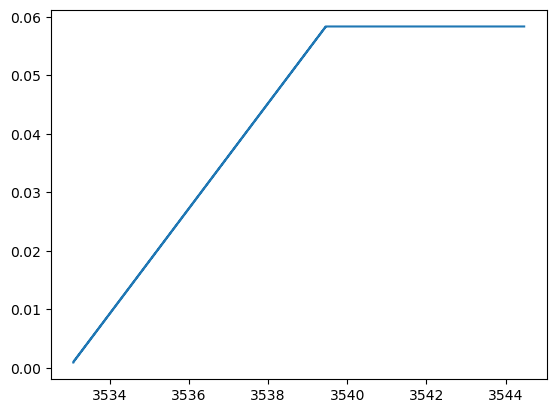

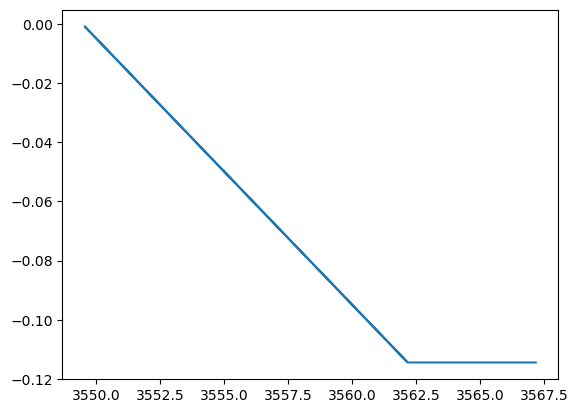

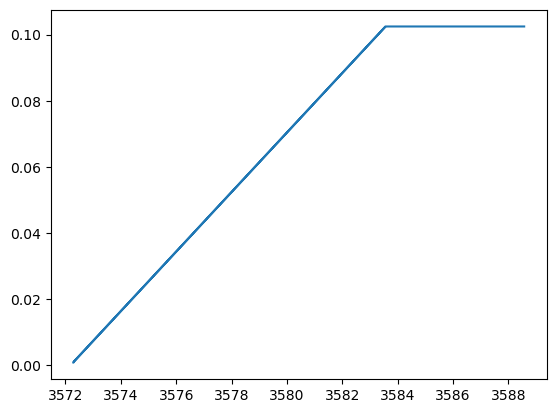

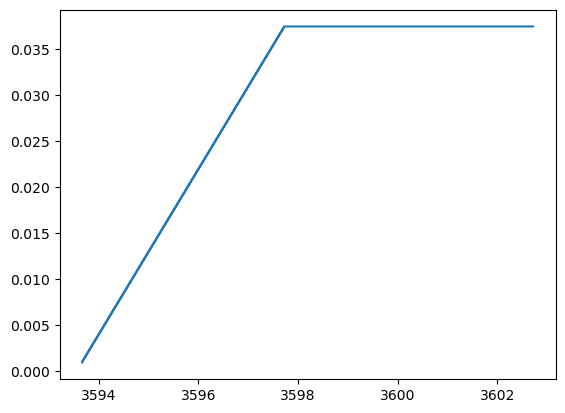

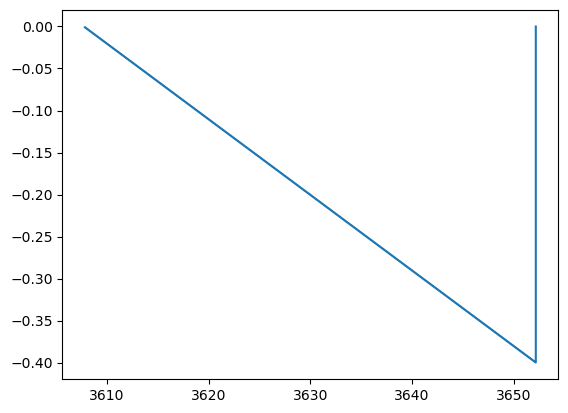

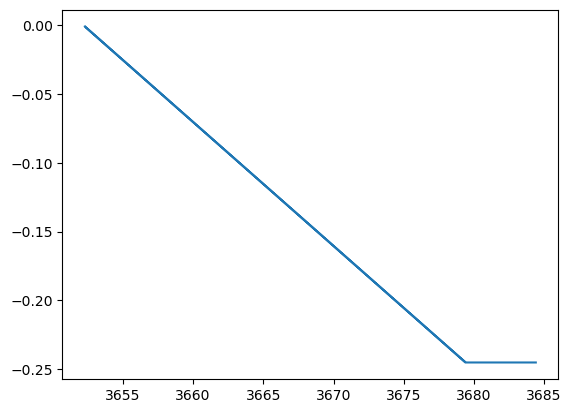

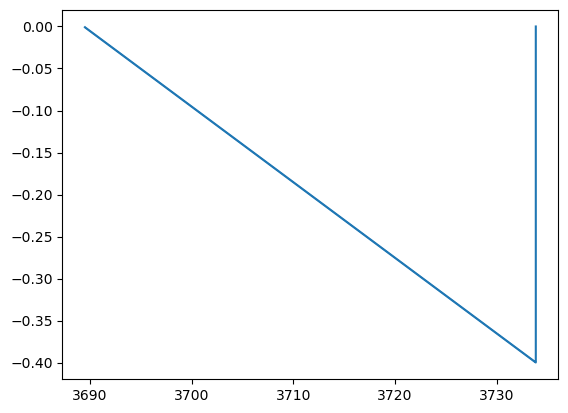

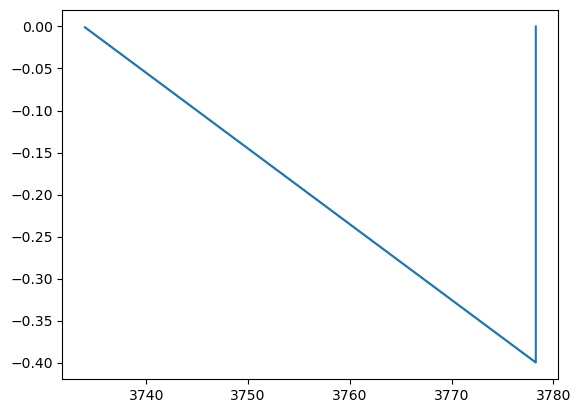

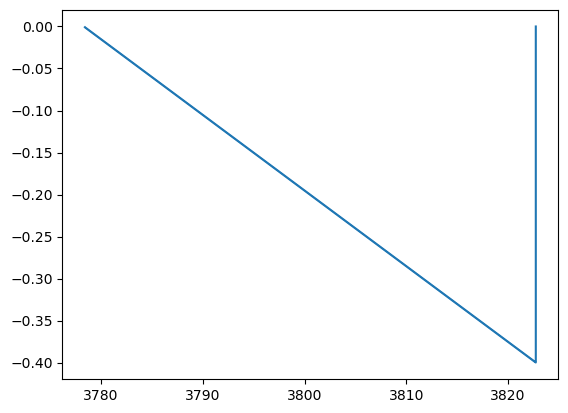

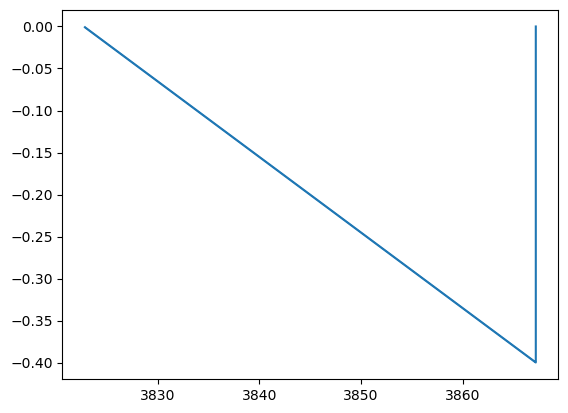

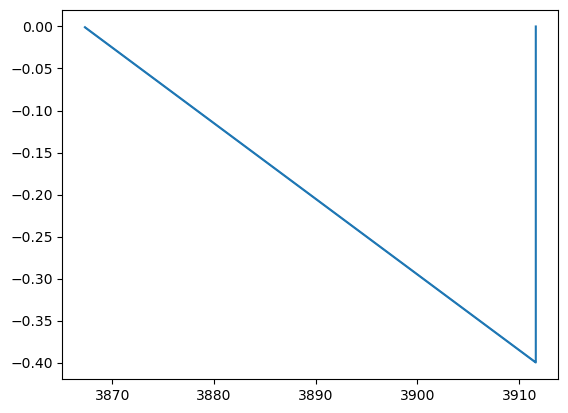

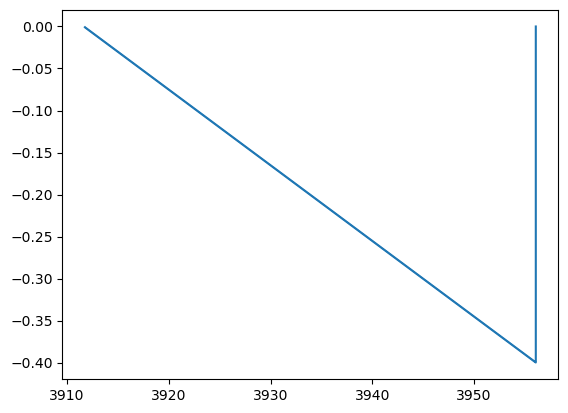

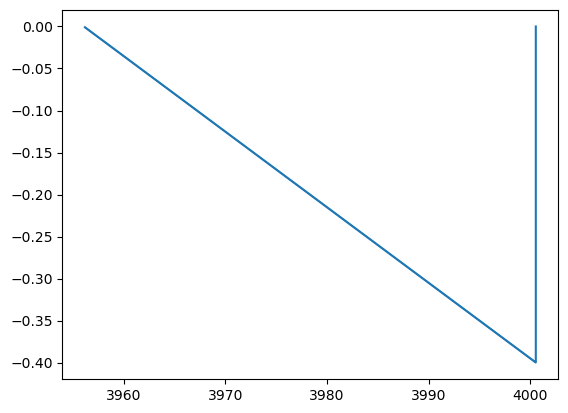

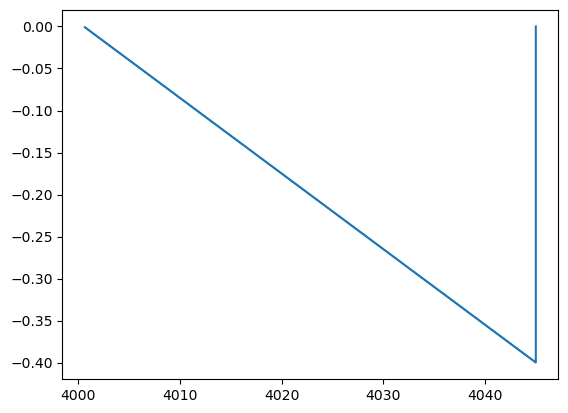

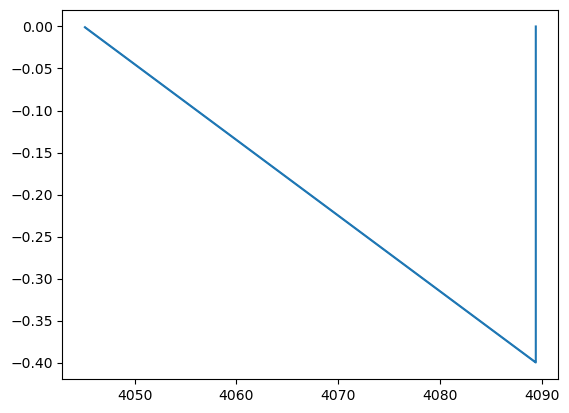

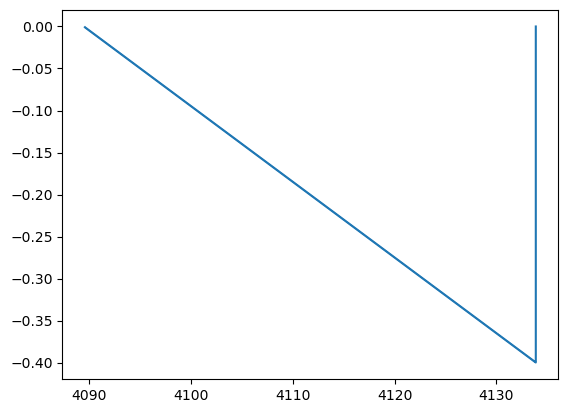

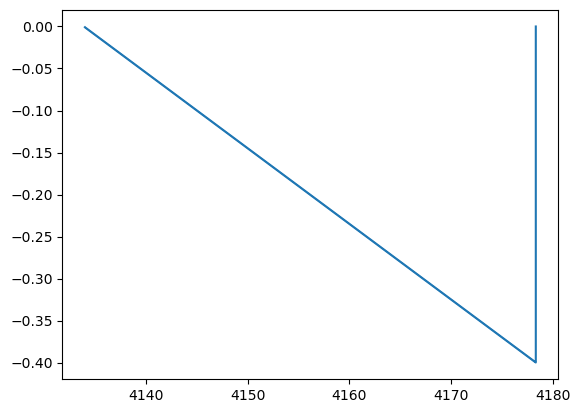

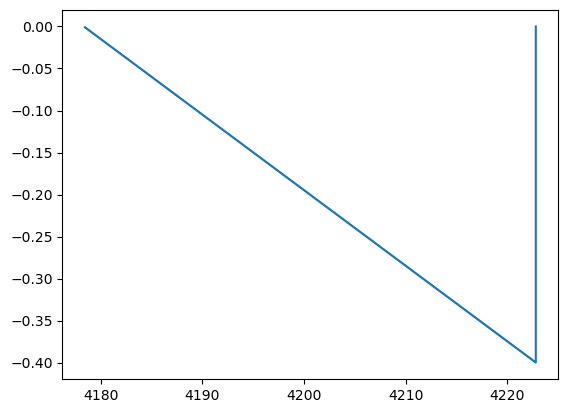

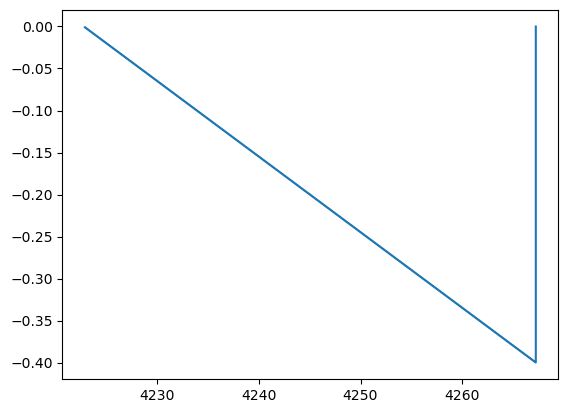

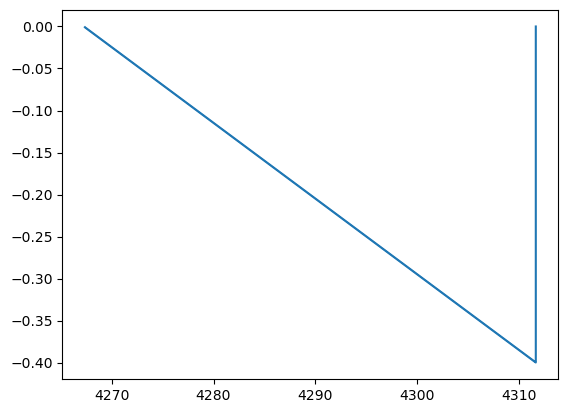

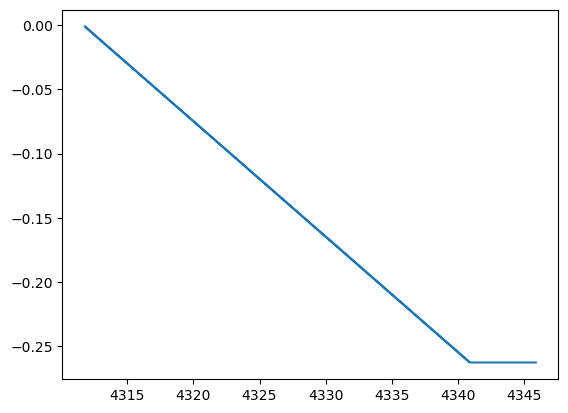

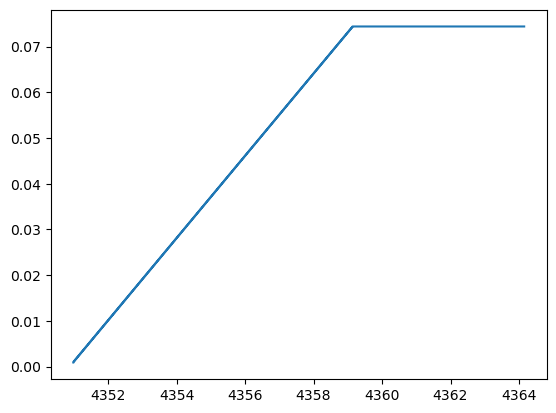

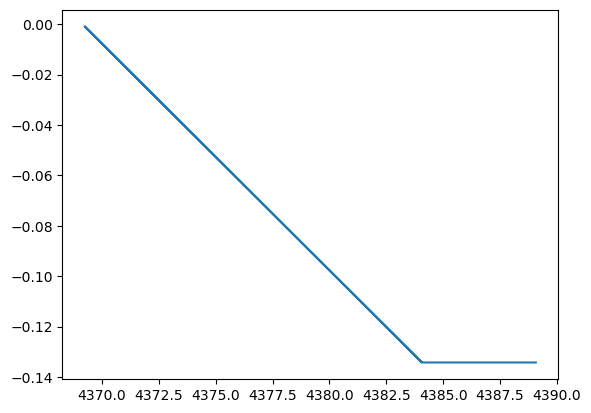

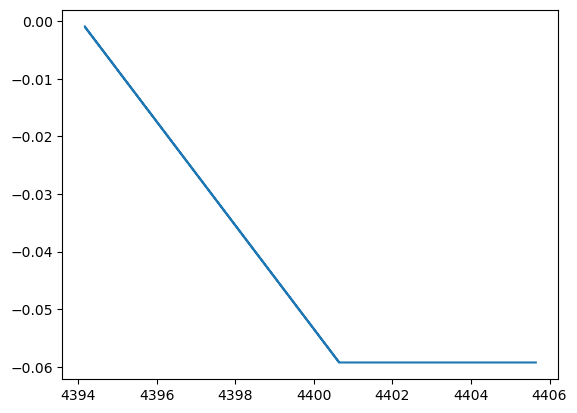

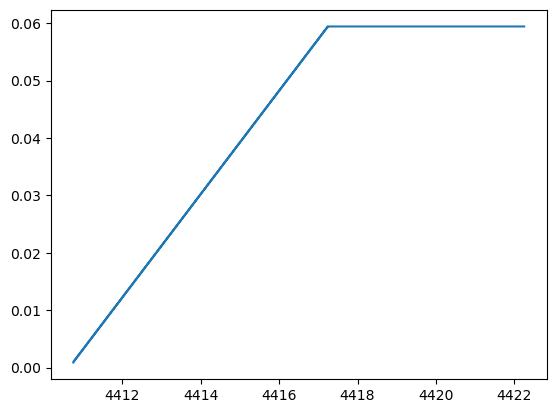

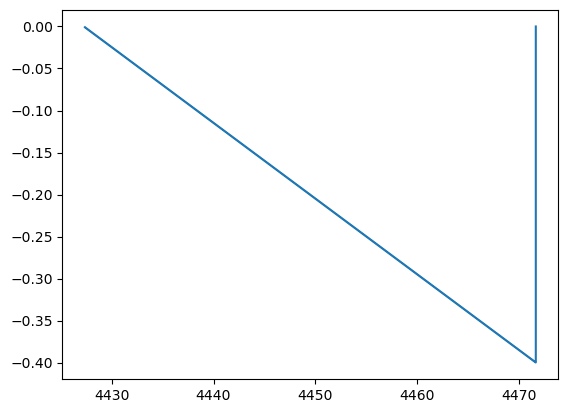

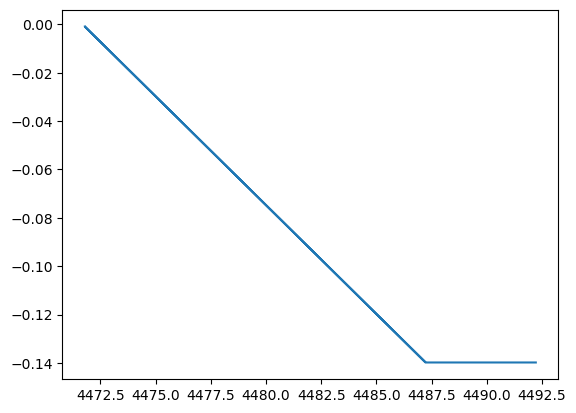

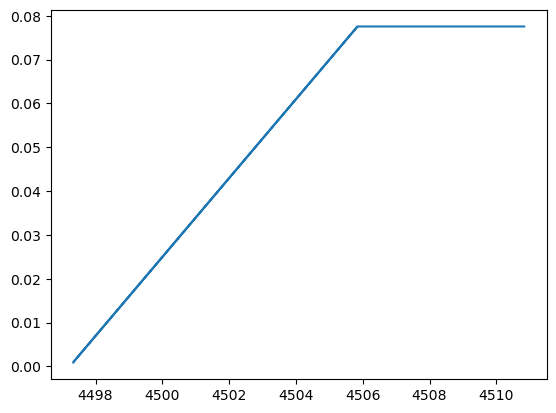

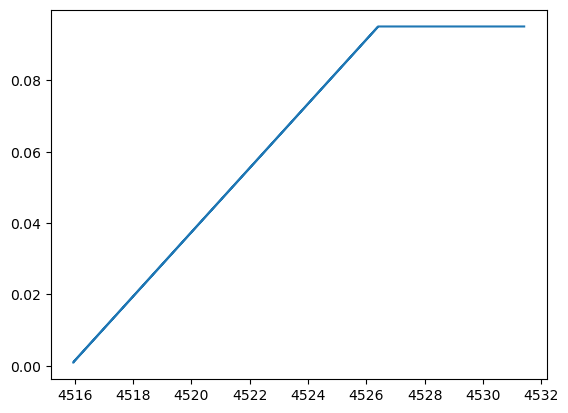

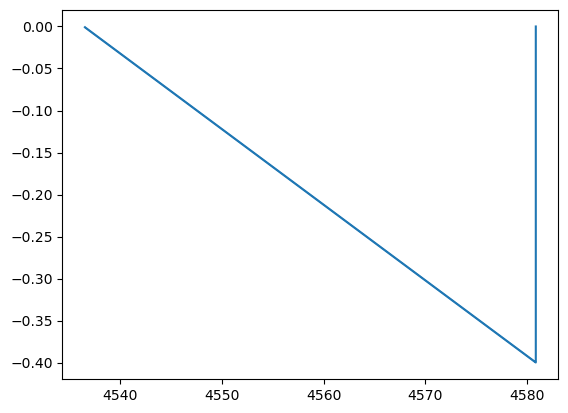

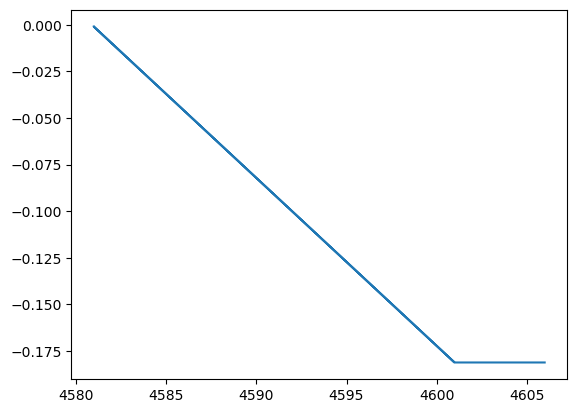

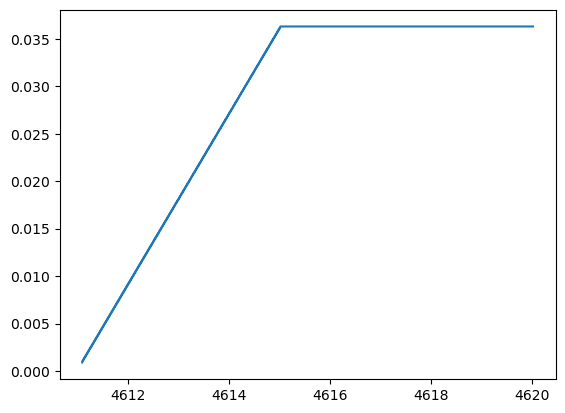

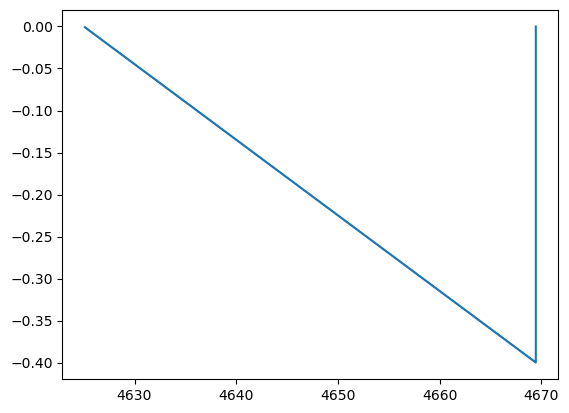

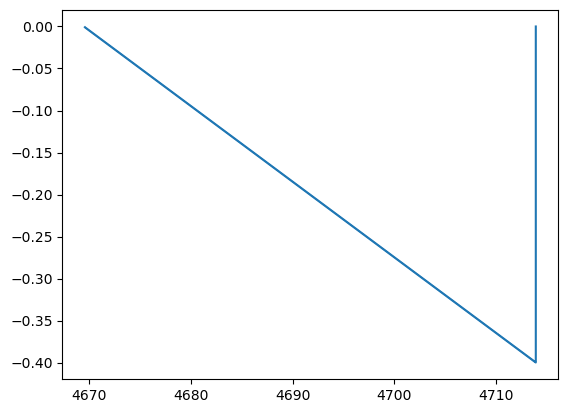

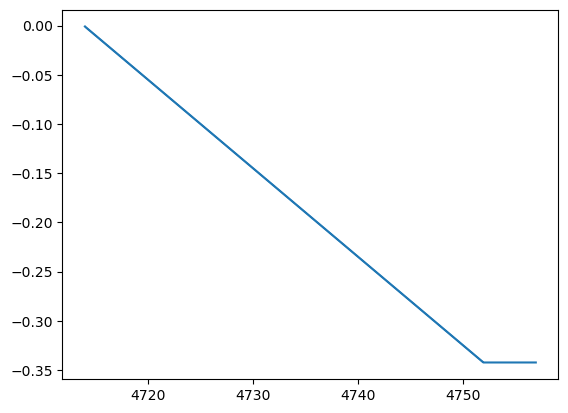

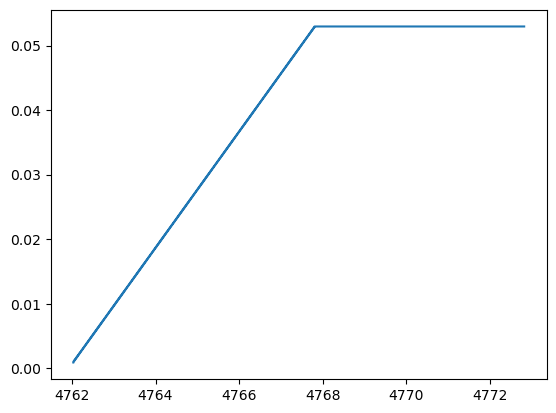

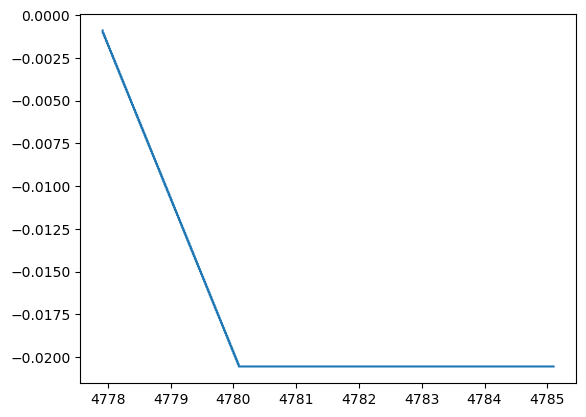

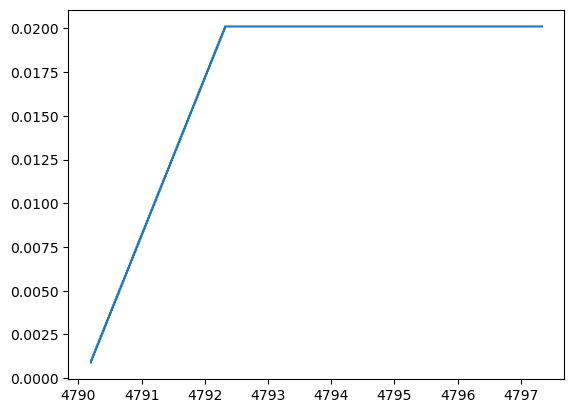

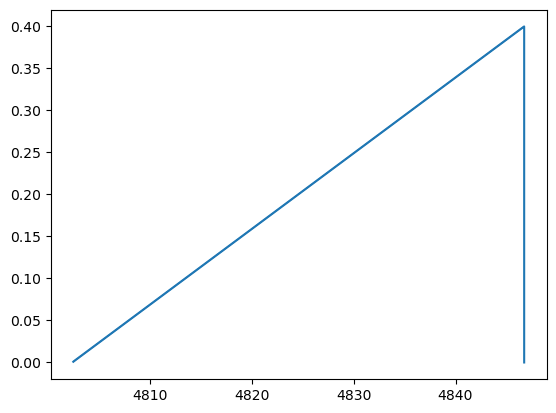

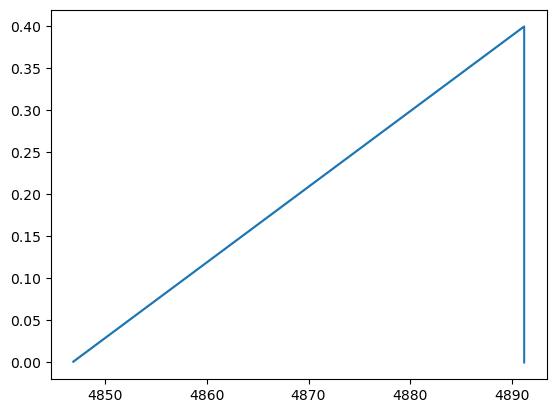

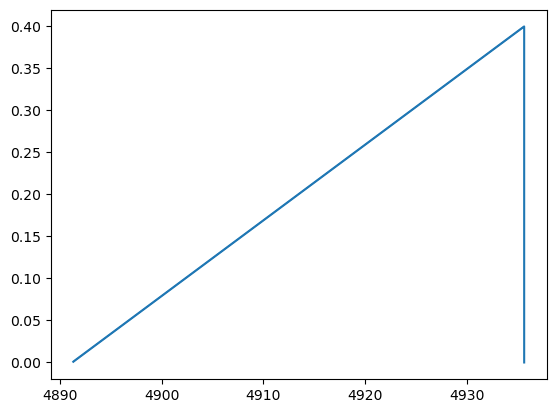

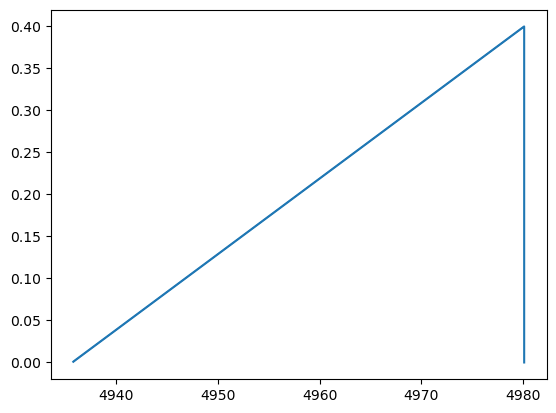

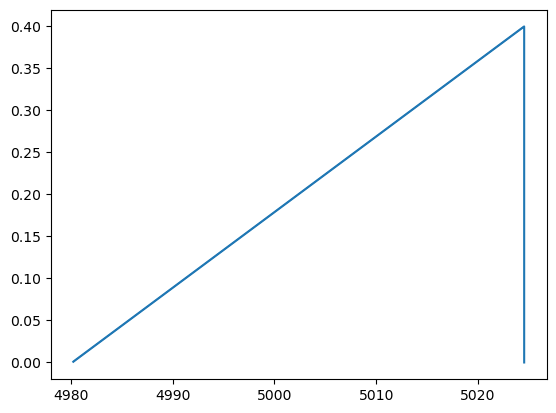

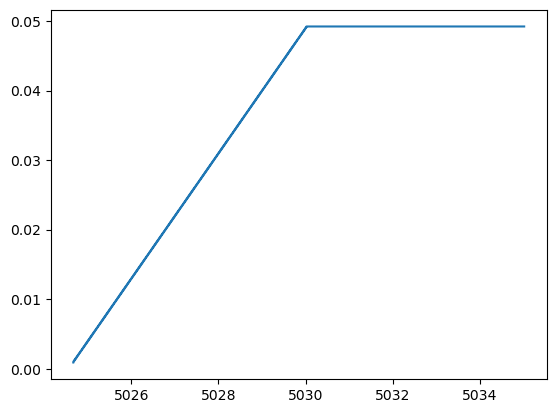

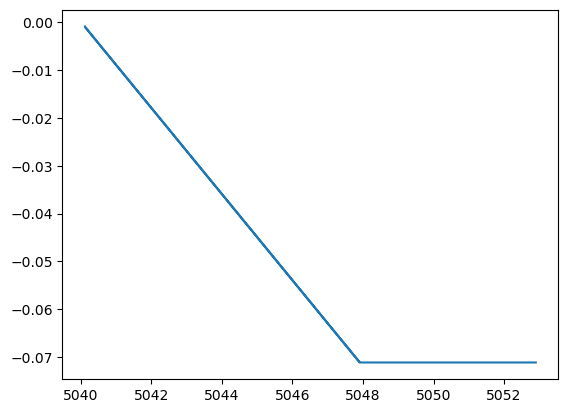

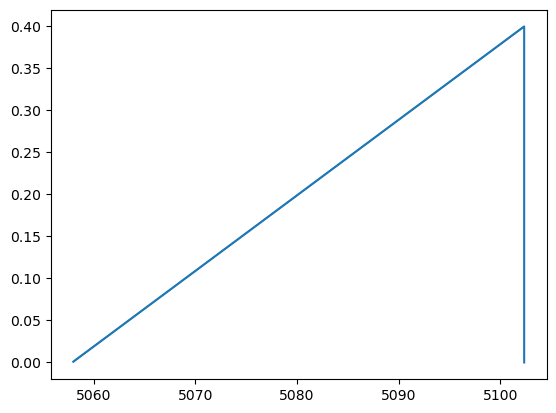

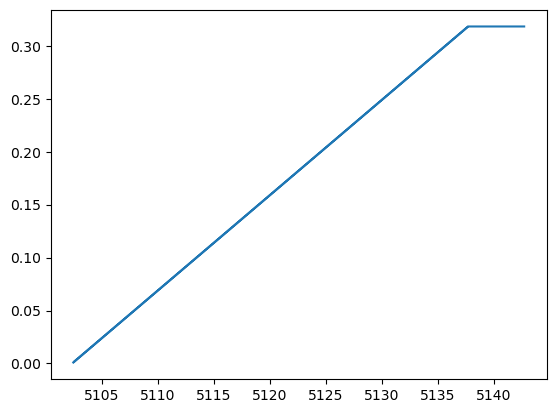

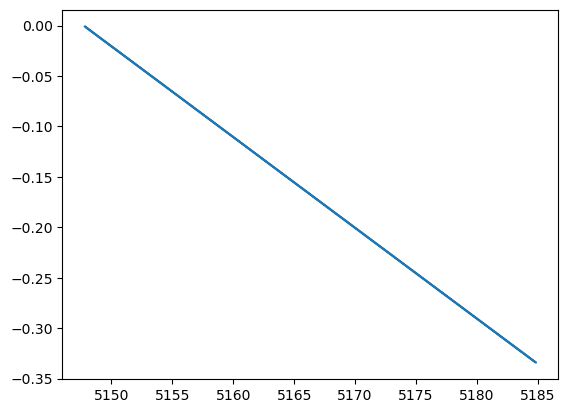

In [23]:
def split_trials(res):
    zero_idx = np.where((res['behav_pos_y'] > -1e-3)&(res['behav_pos_y'] < 1e-3))[0]
    is_intrial = np.ones(res['behav_time'].shape[0], np.int64)
    is_intrial[zero_idx] = 0
    for z in zero_idx:
        if z != 0:
            if np.abs(res['behav_pos_y'][z-1]) > 0.39:
                is_intrial[z] = 1
                
    trial_start = np.where((np.diff(is_intrial) == 1))[0]
    trial_end = np.where((np.diff(is_intrial) == -1))[0]+1
    assert trial_start.shape[0] == trial_end.shape[0]
    return trial_start, trial_end

trial_start, trial_end = split_trials(res)
for start, end in zip(trial_start, trial_end):
    plt.plot(res['behav_time'][start:end], res['behav_pos_y'][start:end])
    plt.show()